# Predicting Government Procurement Failure (PhilGEPS)

**Objective.** Predict, at the time a bid notice is posted, whether a Philippine government procurement will **fail or be cancelled** instead of being **awarded**. An early warning lets procuring entities fix a bid (budget, timeline, specifications) before it fails, which avoids re-bidding delays and wasted procurement effort.

**Target: `Bid Notice Status`**

| Value | Label |
|---|---|
| 1 | Failed or Cancelled |
| 0 | Awarded |

**Data.** PhilGEPS bid notices and awards, 2023 Q1 to 2026 Q2, from the PhilGEPS 1.5 and 2.0 systems (cleaned file `PhilGeps_Cleaned.csv`, about 2.09M line items).

**Approach**
1. Prepare the data: merge the 1.5 and 2.0 column layouts, keep bids with a final outcome, and build a bid ID.
2. Split train and test **by bid**, stratified on the target, plus a second **time-based** split.
3. Preprocess: remove IDs and post-award fields (leakage), analyse missing values, fix a line-item leakage problem, and engineer features. Everything runs inside a scikit-learn `Pipeline`.
4. Tune hyperparameters with **5-fold cross-validation** on a training subsample.
5. Train 7 algorithms across 3 scenarios, then compare them on the test set.
6. Compute feature importance, then take a deeper look at the drivers behind the best model.

**Experiment grid**

| Scenario | Logistic Reg | Ridge (L2) | Lasso (L1) | KNN | Random Forest | XGBoost | HistGB |
|---|---|---|---|---|---|---|---|
| All features (unbalanced) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Undersampling 60/40 | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Time-based train/test split | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |

> **Run note:** restart the kernel and run all cells. A full run takes about 1–1.5 hours and needs about 8 GB of free RAM.

## 1. Setup
Libraries, the plotting palette, and the constants used throughout the notebook. The subsample sizes are set here so they're easy to change:
- **`TUNE_N` (200k bids):** big enough for stable cross-validation curves (about 30k failed bids), small enough to tune 7 algorithms in reasonable time.
- **KNN:** compares every test bid with every training bid, so its cost grows with the square of the data size. It's tuned on `KNN_TUNE_N` bids and trained on `KNN_FIT_N` bids.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, TargetEncoder)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# Custom colour palette (same as earlier coursework)
palette_D = ["#2A9D8F", "#264653", "#E9C46A", "#F4A261", "#E76F51", "#6D597A", "#8AB17D"]
sns.set_palette(palette_D)

# ---- Constants ----
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
TUNE_N = 200_000          # training bids used for hyperparameter tuning (5-fold CV)
KNN_TUNE_N = 50_000       # KNN tuning subsample (distance computations grow quadratically)
KNN_FIT_N = 200_000       # KNN final training subsample
TRAIN_SCORE_N = 200_000   # training bids used to report train scores (faster than all 1.28M)
IMPORTANCE_N = 50_000     # test bids used for permutation importance
CUTOFF = pd.Timestamp("2025-07-01")   # time-based split: train before, test on/after

LABELS = ["Awarded", "Failed/Cancelled"]
MODEL_NAMES = {"logreg": "Logistic Reg", "ridge": "Ridge (L2)", "lasso": "Lasso (L1)", "knn": "KNN",
               "rf": "Random Forest", "xgb": "XGBoost", "hgb": "HistGB"}

## 2. Load and prepare the data

In [2]:
# Reading the cleaned dataset (one row per bid LINE ITEM)
df = pd.read_csv("../data/raw/cleaned_data/PhilGeps_Cleaned.csv", low_memory=False)
print("Rows, columns:", df.shape)

Rows, columns: (2093210, 56)


### 2.1 Merge the PhilGEPS 1.5 and 2.0 layouts
PhilGEPS 2.0 stores some fields under new column names (`Procurement Category`, `Source of Funds`, ...). Each row has a value in only one column of each pair, never both, so the pairs are merged into the 1.5 column name. This takes `Business Category`, `Funding Source` and `Trade Agreement` from 10.8% missing to about 0%, using real values instead of imputed ones. The 2.0 `Delivery Period` (e.g. `"30 Day/s"`) is split into a number (`Contract Duration`) and a unit (`Calendar Type`).

**Target filter.** Only bids with a **final outcome** (Awarded, Failed, Cancelled) are kept. `Active`, `Shortlisted`, `Concluded` and `Published` bids have no outcome yet.

In [3]:
# Each row has a value in one column of the pair or the other, never both -> fill the 1.5 column
MERGE_PAIRS = {
    "Business Category": "Procurement Category",
    "Funding Source":    "Source of Funds",
    "Trade Agreement":   "Applicable Procurement Rules",
    "Area of Delivery":  "Area of Delivery/Project Location",
}
for old_col, new_col in MERGE_PAIRS.items():
    df[old_col] = df[old_col].fillna(df[new_col])

# Align the 2.0 spellings with the 1.5 labels
df["Trade Agreement"] = df["Trade Agreement"].replace({
    "World Bank Procurement Guidelines": "WB Procurement Guidelines",
    "International Executive Agreement": "International / Executive Agreement",
    "Other": "Others",
})
df["Funding Source"] = df["Funding Source"].replace({
    "REGULAR AGENCY FUND (01000000)": "Regular Agency Fund (01000000)",
    "INTERNALLY GENERATED FUNDS (05000000)": "Internally Generated Funds (05000000)",
})
# Civil works projects are grouped under a single label
df["Classification"] = df["Classification"].replace({"Civil Works - Infra Project": "Civil Works"})

# 2.0 'Delivery Period' holds text such as '30 Day/s' -> split into number + unit
dp = df["Delivery Period"].astype("string").str.strip().str.extract(r"^(\d+(?:\.\d+)?)\s*([A-Za-z/]*)")
dp_unit = dp[1].str.lower().str.rstrip("s/").map({"day": "Day/s", "month": "Month/s", "year": "Year/s"})
df["Contract Duration"] = pd.to_numeric(df["Contract Duration"], errors="coerce").fillna(pd.to_numeric(dp[0]))
df["Calendar Type"] = df["Calendar Type"].fillna(dp_unit)

# Target: keep only bids with a final outcome
df["Bid Notice Status"] = df["Bid Notice Status"].replace({"CANCEL_APPROVED": "Cancelled"})
print("Before filtering:\n", df["Bid Notice Status"].value_counts(dropna=False), "\n")
df = df[df["Bid Notice Status"].isin(["Awarded", "Failed", "Cancelled"])].reset_index(drop=True)
print("After filtering:", df.shape)

Before filtering:
 Bid Notice Status
Awarded        1742602
Failed          161797
Cancelled       158747
Active           28942
Shortlisted        937
CONCLUDED          175
Published            7
NaN                  3
Name: count, dtype: int64 



After filtering: (2063146, 56)


### 2.2 Bid ID
Each row is a **line item**, and all line items of one bid share the same status. If rows were split at random, items from the same bid would land in both train and test, and the score would be too optimistic. The bid ID keeps each bid in a single split. The bid reference number is used where it exists; otherwise the 2.0 solicitation number; otherwise entity + title + published date.

In [4]:
bid_ref = df["Bid Reference No."].where(df["Bid Reference No."] > 0)
bid_id = "ref_" + bid_ref.astype("Int64").astype("string")
bid_id = bid_id.fillna("sol_" + df["Solicitation No."].astype("string"))
# Bid ref 0 and no solicitation no.: fall back to PE + title + published date
fallback = ("pe_" + df["Procuring Entity (PE)"].astype(str) + "|" + df["Notice Title"].astype(str)
            + "|" + df["Published Date"].astype(str))
df["Bid ID"] = bid_id.fillna(fallback)

print("Rows:", len(df), "| Bids:", df["Bid ID"].nunique())
print("Bids with more than one status:", (df.groupby("Bid ID")["Bid Notice Status"].nunique() > 1).sum())

Rows: 2063146 | Bids: 1600755


Bids with more than one status: 3


## 3. Target and features
`y = 1` if the bid Failed or was Cancelled, `0` if Awarded. About **15%** of line items are failures, so the classes are imbalanced. For that reason this notebook uses **PR AUC** (average precision for the Failed/Cancelled class) as its main metric. Accuracy would reach 85% even for a model that never predicts failure.

Bid Notice Status
Awarded (0)             0.8446
Failed/Cancelled (1)    0.1554
Name: proportion, dtype: float64


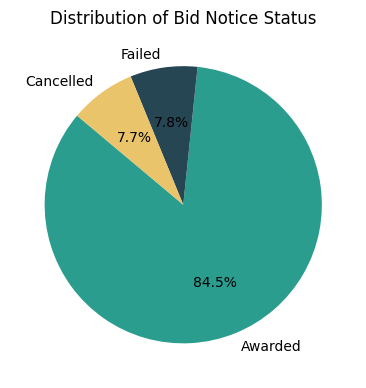

In [5]:
TARGET = "Bid Notice Status"

y = df[TARGET].isin(["Failed", "Cancelled"]).astype(int)   # 1 = failed/cancelled, 0 = awarded
X = df.drop(columns=[TARGET])
groups = df["Bid ID"]

print(y.value_counts(normalize=True).rename({0: "Awarded (0)", 1: "Failed/Cancelled (1)"}).round(4))

# Distribution of the original status labels
target_counts = df[TARGET].value_counts()
plt.figure(figsize=(4.5, 4.5))
plt.pie(target_counts, labels=target_counts.index, autopct="%1.1f%%", startangle=140, colors=palette_D)
plt.title("Distribution of Bid Notice Status")
plt.show()

## 4. Train/test split
The split is **stratified on `y`**, so train and test keep the same failure rate. It's done on **bid IDs** rather than rows, so no bid appears in both sets: one label per bid, 80/20, `random_state=42`. A second, time-based split is built in section 5.5, after the data is reduced to one row per bid.

In [6]:
bid_labels = y.groupby(groups).first()            # one label per bid
train_bids, test_bids = train_test_split(
    bid_labels.index, test_size=TEST_SIZE, stratify=bid_labels, random_state=RANDOM_STATE
)

train_mask = groups.isin(train_bids)
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Failure rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))
print("Bids in both splits:", len(set(groups[train_mask]) & set(groups[~train_mask])))

Train: (1647334, 56) | Test: (415812, 56)
Failure rate  train: 0.1554  test: 0.1551


Bids in both splits: 0


## 5. Data preprocessing
### 5.1 Remove IDs and award/awardee details
Award and awardee fields (award date, contract amount, awardee name, ...) are only filled in **after** a bid is awarded. Keeping them would leak the answer into the features. Also removed:
- IDs and free-text titles
- the 2.0 columns that were merged in 2.1
- free-text item names (838k+ unique values)

Every step is a scikit-learn transformer, so the same code runs on train, test and new bids inside the final `Pipeline`. `X_train` itself keeps all columns: the columns are dropped **inside** the pipeline.

In [7]:
FEATURES_TO_REMOVE = [
    # IDs and free-text titles
    "Bid Reference No.", "Notice Title", "Solicitation No.", "Bid ID",
    # award and awardee details (leakage: only known after the outcome)
    "Award Reference No.", "Award Title", "UNSPSC Code", "UNSPSC Description",
    "Published Date(Award)", "Award Date", "Contract Amount", "Award Notice Status",
    "Notice to Proceed Date", "Contract Effectivity Date", "Contract End Date",
    "Awardee OrgID", "Awardee Organization Name", "Country of Awardee", "Region of Awardee",
    "Province of Awardee", "City/Municipality of Awardee", "Awardee Size", "Awardee Joint Venture",
    "Award Notice Status (Item)", "Item/Lot Name.1",
    # 2.0 columns already merged into their 1.5 equivalents
    "Procurement Category", "Source of Funds", "Applicable Procurement Rules",
    "Area of Delivery/Project Location", "Delivery Period", "Lot Type",
    # free-text item fields
    "Item Name", "Item Description",
]


class DropColumns(BaseEstimator, TransformerMixin):
    """Pipeline step that drops the given columns (ignores any that are absent)."""

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=[c for c in self.columns if c in X.columns])


X_train_red = DropColumns(FEATURES_TO_REMOVE).fit_transform(X_train)   # copy for inspection only
print(X_train_red.shape)
print(X_train_red.columns.tolist())

(1647334, 23)
['Procuring Entity (PE)', 'Region', 'Province', 'City/Municipality', 'Government Branch', 'PE Organization Type', 'PE Organization Type (Grouped)', 'Classification', 'Procurement Mode', 'Business Category', 'Funding Source', 'Funding Instrument', 'Trade Agreement', 'Approved Budget of the Contract', 'Published Date', 'Closing Date', 'Area of Delivery', 'Contract Duration', 'Calendar Type', 'Line Item No', 'Quantity', 'UOM', 'Item Budget']


### 5.2 Categorical and numerical features
Categorical features are split by cardinality, because each group needs a different encoding:
- **Low cardinality (≤ 100 levels):** one category per level.
- **High cardinality** (`Procuring Entity` has about 24k levels): **target encoding**, which replaces each level with its smoothed historical failure rate.

In [8]:
DATE_FEATURES = ["Published Date", "Closing Date"]
NUM_FEATURES = ["Approved Budget of the Contract", "Contract Duration", "Line Item No",
                "Quantity", "Item Budget"]
CAT_FEATURES = [c for c in X_train_red.columns if c not in NUM_FEATURES + DATE_FEATURES]

card = X_train_red[CAT_FEATURES].nunique().sort_values()
print("Categorical cardinality:\n", card, "\n")

HIGH_CARD_THRESHOLD = 100
LOW_CARD_CAT = card[card <= HIGH_CARD_THRESHOLD].index.tolist()
HIGH_CARD_CAT = card[card > HIGH_CARD_THRESHOLD].index.tolist()
print("Low-cardinality :", LOW_CARD_CAT)
print("High-cardinality:", HIGH_CARD_CAT)
print("Numerical       :", NUM_FEATURES)
print("Dates           :", DATE_FEATURES)

Categorical cardinality:
 Calendar Type                         3
Classification                        4
PE Organization Type (Grouped)        5
Funding Instrument                    6
Government Branch                     7
Trade Agreement                       7
Funding Source                       12
PE Organization Type                 16
Region                               26
Procurement Mode                     34
UOM                                  65
Province                             95
Area of Delivery                    163
Business Category                   503
City/Municipality                  1340
Procuring Entity (PE)             23988
dtype: int64 

Low-cardinality : ['Calendar Type', 'Classification', 'PE Organization Type (Grouped)', 'Funding Instrument', 'Government Branch', 'Trade Agreement', 'Funding Source', 'PE Organization Type', 'Region', 'Procurement Mode', 'UOM', 'Province']
High-cardinality: ['Area of Delivery', 'Business Category', 'City/Municipality

### 5.3 Missing value analysis (train set only)
Before imputing, we check whether **missingness itself predicts the target**. If a value is missing because of what happened *after* posting, the missing value is leakage, not a feature. The analysis uses the training set only.

In [9]:
miss = pd.DataFrame({
    "n_missing": X_train_red.isna().sum(),
    "pct_missing": (X_train_red.isna().mean() * 100).round(2),
})
# Failure rate when the value is missing vs present
miss["fail_rate_if_missing"] = [y_train[X_train_red[c].isna()].mean() for c in miss.index]
miss["fail_rate_if_present"] = [y_train[X_train_red[c].notna()].mean() for c in miss.index]
miss = miss[miss["n_missing"] > 0].sort_values("pct_missing", ascending=False)
print("Overall failure rate: %.3f" % y_train.mean())
display(miss.round(3))

# Line-item fields go missing together (bids exported without their line items)
item_cols = ["Line Item No", "Quantity", "Item Budget", "UOM"]
print("Rows missing ALL item fields:", X_train_red[item_cols].isna().all(axis=1).sum(),
      "| missing ANY:", X_train_red[item_cols].isna().any(axis=1).sum())

Overall failure rate: 0.155


,n_missing,pct_missing,fail_rate_if_missing,fail_rate_if_present
Calendar Type,153133,9.30,0.081,0.163
Area of Delivery,146686,8.90,0.144,0.157
Line Item No,141277,8.58,1.000,0.076
Quantity,141277,8.58,1.000,0.076
UOM,141318,8.58,1.000,0.076
Item Budget,141276,8.58,1.000,0.076
Closing Date,96870,5.88,0.000,0.165
Contract Duration,74306,4.51,0.167,0.155
Published Date,44222,2.68,0.000,0.160
Funding Instrument,26395,1.60,0.298,0.153


Rows missing ALL item fields: 141276 | missing ANY: 141318


### 5.4 Decisions from the missing value analysis

| Finding | Meaning | Action |
|---|---|---|
| Item fields (`Line Item No`, `Quantity`, `UOM`, `Item Budget`) missing → **100% failed** | About half of all failed or cancelled bids were exported without their line items. This is an export artifact: a new bid always has items. | **Drop the item columns** and keep **one row per bid**. Keeping them gave a falsely high ROC AUC of 0.95 |
| `Published Date` / `Closing Date` missing → **0% failed** | These are direct and negotiated modes (lease, direct contracting, emergency) that are never publicly posted. The mode is known when the bid is created. | Keep. Date features become NaN, and the median imputer adds a "was missing" flag |
| `Calendar Type` / `Contract Duration` missing | Rate differs from the average, but only mildly | Keep. Missing becomes its own category or a "was missing" flag |
| `Area of Delivery` missing (8.9%) | Rate is close to the average | `"Missing"` becomes its own category |
| `Funding Instrument` missing (1.6%) → 30% failed | Missingness carries information | `"Missing"` becomes its own category |

**Imputation strategy** (fitted on the training data only, inside the pipeline):
- **Categorical:** fill with a `"Missing"` category rather than the most frequent value, because missingness here often carries meaning.
- **Numerical:** fill with the **median**, because budgets are heavily skewed, and add a "was missing" indicator so the model still knows the value was absent.

In [10]:
# Line-item fields leak the target (see table above) -> drop them
LEAKY_FEATURES = ["Line Item No", "Quantity", "UOM", "Item Budget"]

# Without the item columns, every line item of a bid is the same row -> keep one row per bid.
# (Bids never span train/test, so this is done separately on each split.)
keep_train = ~X_train["Bid ID"].duplicated()
keep_test = ~X_test["Bid ID"].duplicated()
X_train, y_train = X_train[keep_train], y_train[keep_train]
X_test, y_test = X_test[keep_test], y_test[keep_test]

NUM_FEATURES = [c for c in NUM_FEATURES if c not in LEAKY_FEATURES]
LOW_CARD_CAT = [c for c in LOW_CARD_CAT if c not in LEAKY_FEATURES]
HIGH_CARD_CAT = [c for c in HIGH_CARD_CAT if c not in LEAKY_FEATURES]
CAT_FEATURES = LOW_CARD_CAT + HIGH_CARD_CAT
INPUT_COLUMNS = CAT_FEATURES + NUM_FEATURES + DATE_FEATURES   # raw columns the models actually use

print("Bid-level train:", X_train.shape, "| test:", X_test.shape)
print("Failure rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))

Bid-level train: (1280604, 56) | test: (320151, 56)
Failure rate  train: 0.1515  test: 0.1515


### 5.5 Time-based split
The random split measures how well the model works on bids **like the ones it has seen**. In real use, though, the model predicts **future** bids from past ones. The time-based split trains on bids published **before 1 July 2025** and tests on bids from **1 July 2025 to June 2026**. It uses the same bid-level data and the same features.

- **What it tests:** whether the patterns hold over time. This is especially relevant for the procuring entity's failure rate, which can then only be learned from past bids.
- **Bids with no date:** a bid with neither a published nor a closing date (direct or negotiated modes) goes to the training set.
- **Caveat:** about 29k bids still had an *Active* status, mostly from 2025, and were excluded because their outcome is unknown. The recent test period may therefore lean towards bids that were resolved quickly.

In [11]:
def parse_date(s):
    """Parse both date layouts: '23/09/2025' (1.5 files) and '18-Apr-2026' / '19-Mar-2026 09:00 AM' (2026 2.0 files)."""
    s = s.astype("string").str.strip()
    out = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return out.fillna(pd.to_datetime(s.str[:11], format="%d-%b-%Y", errors="coerce"))


# All bids at bid level (one row per bid), then split on the bid's date
X_bid = pd.concat([X_train, X_test])
y_bid = pd.concat([y_train, y_test])
bid_date = parse_date(X_bid["Published Date"]).fillna(parse_date(X_bid["Closing Date"]))

time_train = (bid_date < CUTOFF) | bid_date.isna()     # undated bids go to train
X_train_t, X_test_t = X_bid[time_train], X_bid[~time_train]
y_train_t, y_test_t = y_bid[time_train], y_bid[~time_train]

print("Time split  train:", X_train_t.shape, "| test:", X_test_t.shape)
print("Train dates: %s to %s" % (bid_date[time_train].min().date(), bid_date[time_train].max().date()))
print("Test dates : %s to %s" % (bid_date[~time_train].min().date(), bid_date[~time_train].max().date()))
print("Failure rate  train: %.4f  test: %.4f" % (y_train_t.mean(), y_test_t.mean()))

# Free memory: the line-item level frames are no longer needed
del df, X, X_bid, y_bid

Time split  train: (1321281, 56) | test: (279474, 56)
Train dates: 2023-01-01 to 2025-06-30
Test dates : 2025-07-01 to 2026-06-30
Failure rate  train: 0.1416  test: 0.1981


## 6. Feature engineering
Feature engineering is a pipeline step that works **row by row** and never sees the target, so it can't leak. Each engineered feature, and why it may predict failure:

| Feature | Why it may predict failure |
|---|---|
| `bid_window_days` = closing − published | A short window means fewer bidders, so a higher chance of no eligible bid |
| `pub_month`, `pub_dayofweek`, `is_q4` | Year-end rush to use the budget, and seasonality |
| `duration_days` (Day/Month/Year → days) | Puts every contract duration on one scale |
| `log_abc` | The approved budget spans many orders of magnitude, and a budget that is too low is a common cause of failure |
| `delivery_outside_pe_province` | Remote delivery attracts fewer suppliers |

In [12]:
class ProcurementFeatures(BaseEstimator, TransformerMixin):
    """Turns raw bid columns into model features. Row-wise only, so it learns nothing from y."""

    UNIT_DAYS = {"Day/s": 1, "Month/s": 30, "Year/s": 365}

    def __init__(self, cat_features):
        self.cat_features = cat_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        pub = parse_date(X["Published Date"])
        close = parse_date(X["Closing Date"])

        # Timing: short bidding windows and year-end rush may raise failure risk
        window = (close - pub).dt.days
        X["bid_window_days"] = window.where(window >= 0)
        X["pub_month"] = pub.dt.month
        X["pub_dayofweek"] = pub.dt.dayofweek
        X["is_q4"] = (pub.dt.quarter == 4).astype(float).where(pub.notna())

        # Duration in days (missing unit is almost always days)
        unit_days = X["Calendar Type"].map(self.UNIT_DAYS).fillna(1)
        X["duration_days"] = X["Contract Duration"] * unit_days

        # Budget on a log scale (it spans several orders of magnitude)
        X["log_abc"] = np.log1p(X["Approved Budget of the Contract"].clip(lower=0))

        # Delivery location differs from the procuring entity's province
        X["delivery_outside_pe_province"] = (
            X["Area of Delivery"].notna() & (X["Area of Delivery"] != X["Province"])
        ).astype(float)

        X = X.drop(columns=DATE_FEATURES + ["Contract Duration", "Approved Budget of the Contract"])
        # Make every categorical column plain strings (keeps NaN) so the encoders don't see mixed types
        for c in self.cat_features:
            X[c] = X[c].where(X[c].isna(), X[c].astype(str))
        return X


ENGINEERED_NUM = ["bid_window_days", "pub_month", "pub_dayofweek", "is_q4", "duration_days",
                  "log_abc", "delivery_outside_pe_province"]

# Quick look at the engineered features on a few training bids
display(ProcurementFeatures(CAT_FEATURES).transform(X_train[INPUT_COLUMNS].head())[ENGINEERED_NUM])

,bid_window_days,pub_month,pub_dayofweek,is_q4,duration_days,log_abc,delivery_outside_pe_province
0,NaN,NaN,NaN,NaN,2.0,11.100451,1.0
1,NaN,3.0,4.0,0.0,15.0,11.223923,0.0
2,NaN,1.0,4.0,0.0,7.0,14.693253,0.0
4,NaN,NaN,NaN,NaN,7.0,10.581198,0.0
5,NaN,1.0,1.0,0.0,<NA>,10.714440,0.0


## 7. Modelling pipelines
Every model is one pipeline, so all preprocessing is **fitted on the training data only**, including inside each cross-validation fold:

`[undersampler] → drop columns → engineer features → impute and encode → classifier`

Two preprocessing variants are needed, because the algorithm families read features differently:

| | Tree models (RF, XGBoost, HistGB) | Linear models and KNN |
|---|---|---|
| Numerical | Median imputation + "was missing" flag | Same, **then standardised** (coefficients and distances depend on scale) |
| Low-cardinality categorical | `"Missing"` category → **ordinal codes** (trees split on them; HistGB treats them as true categories) | `"Missing"` category → **one-hot** (ordinal codes would imply a false order) |
| High-cardinality categorical | `"Missing"` → **target encoding** (cross-fitted, so a row never sees its own label) | Same, then standardised |

Rare categories (fewer than 50 bids) are grouped together. For KNN, the sparse one-hot matrix is converted to dense `float32` so the distance calculations are fast.

**Undersampling scenario.** `RandomUnderSampler(sampling_strategy=0.667)` keeps every failed bid and randomly drops awarded bids until the training data is **60% Awarded / 40% Failed** (0.667 = 40/60). Because the sampler is an `imblearn` pipeline step, it runs only during `fit`: the test set always keeps its real class split.

In [13]:
def make_preprocessor(kind):
    """'tree' = ordinal codes (dense DataFrame); 'linear' = one-hot + scaling (sparse matrix)."""
    if kind == "tree":
        num = SimpleImputer(strategy="median", add_indicator=True)
        low = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                  min_frequency=50, dtype=np.float64))])
        high = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                         ("encode", TargetEncoder(target_type="binary", random_state=RANDOM_STATE))])
    else:
        num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
        low = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50))])
        high = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                         ("encode", TargetEncoder(target_type="binary", random_state=RANDOM_STATE)),
                         ("scale", StandardScaler())])
    ct = ColumnTransformer([("num", num, ENGINEERED_NUM), ("low_cat", low, LOW_CARD_CAT),
                            ("high_cat", high, HIGH_CARD_CAT)],
                           remainder="drop", verbose_feature_names_out=False)
    return ct.set_output(transform="pandas") if kind == "tree" else ct


def to_dense32(X):
    """KNN: sparse one-hot matrix -> dense float32 (much faster distance computations)."""
    return X.toarray().astype(np.float32) if hasattr(X, "toarray") else np.asarray(X, dtype=np.float32)


def make_classifier(algo, params):
    """Classifier for each algorithm; `params` holds the tuned hyperparameter."""
    p = dict(params)
    if algo == "logreg":   # plain logistic regression, no penalty
        return LogisticRegression(penalty=None, max_iter=1000)
    if algo == "ridge":    # L2-penalised logistic regression
        return LogisticRegression(penalty="l2", C=p["C"], max_iter=1000)
    if algo == "lasso":    # L1-penalised logistic regression (saga supports L1 on large sparse data)
        return LogisticRegression(penalty="l1", C=p["C"], solver="saga", max_iter=200, tol=1e-3)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=p["n_neighbors"], algorithm="brute", n_jobs=-1)
    if algo == "rf":
        return RandomForestClassifier(n_estimators=100, max_depth=p["max_depth"], min_samples_leaf=20,
                                      max_samples=0.3, n_jobs=-1, random_state=RANDOM_STATE)
    if algo == "xgb":
        return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=p["max_depth"],
                             tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE)
    if algo == "hgb":      # same settings as the 02_D_modeling baseline (+ tuned max_leaf_nodes)
        return HistGradientBoostingClassifier(categorical_features=LOW_CARD_CAT, max_iter=300,
                                              learning_rate=0.1, early_stopping=True,
                                              max_leaf_nodes=p["max_leaf_nodes"], random_state=RANDOM_STATE)
    raise ValueError(algo)


def make_model(algo, params, undersample=False):
    """Full pipeline: [undersampler] -> drop columns -> features -> preprocess -> [dense] -> classifier."""
    kind = "tree" if algo in ("rf", "xgb", "hgb") else "linear"
    steps = []
    if undersample:
        steps.append(("sample", RandomUnderSampler(sampling_strategy=0.667, random_state=RANDOM_STATE)))
    steps += [("drop", DropColumns(FEATURES_TO_REMOVE + LEAKY_FEATURES)),
              ("features", ProcurementFeatures(CAT_FEATURES)),
              ("preprocess", make_preprocessor(kind))]
    if algo == "knn":
        steps.append(("dense", FunctionTransformer(to_dense32, accept_sparse=True)))
    steps.append(("clf", make_classifier(algo, params)))
    return ImbPipeline(steps)


def fit_pipeline(model, X, y):
    """Fit the pipeline step by step and also return the training data exactly as the classifier saw it.

    Why: the TargetEncoder cross-fits during training (a bid never sees its own label), but calling
    predict() on the training rows would encode them with the full-fit values, so each bid WOULD see
    its own label and the train score would be inflated. Train scores are therefore computed on the
    returned (Xt, yt), which hold the cross-fitted encodings and, if undersampling is on, the resampled rows.
    """
    Xt, yt = X, y
    for _, step in model.steps[:-1]:
        if hasattr(step, "fit_resample"):      # sampler: changes the training rows (fit only)
            Xt, yt = step.fit_resample(Xt, yt)
        else:
            Xt = step.fit_transform(Xt, yt)
    model.steps[-1][1].fit(Xt, yt)
    return model, Xt, np.asarray(yt)


def take_rows(Xt, idx):
    """Row selection that works for DataFrames, sparse matrices and arrays."""
    return Xt.iloc[idx] if hasattr(Xt, "iloc") else Xt[idx]


make_model("hgb", {"max_leaf_nodes": 31})

Pipeline(steps=[('drop',
                 DropColumns(columns=['Bid Reference No.', 'Notice Title',
                                      'Solicitation No.', 'Bid ID',
                                      'Award Reference No.', 'Award Title',
                                      'UNSPSC Code', 'UNSPSC Description',
                                      'Published Date(Award)', 'Award Date',
                                      'Contract Amount', 'Award Notice Status',
                                      'Notice to Proceed Date',
                                      'Contract Effectivity Date',
                                      'Contract End Date', 'Awardee OrgID',
                                      'Awardee Organization Name',
                                      'C...
                                   verbose_feature_names_out=False)),
                ('clf',
                 HistGradientBoostingClassifier(categorical_features=['Calendar '
                                                                      'Type',
                                                                      'Classification',
                                                                      'PE '
                                                                      'Organization '
                                                                      'Type '
                                                                      '(Grouped)',
                                                                      'Funding '
                                                                      'Instrument',
                                                                      'Government '
                                                                      'Branch',
                                                                      'Trade '
                                                                      'Agreement',
                                                                      'Funding '
                                                                      'Source',
                                                                      'PE '
                                                                      'Organization '
                                                                      'Type',
                                                                      'Region',
                                                                      'Procurement '
                                                                      'Mode',
                                                                      'Province'],
                                                early_stopping=True,
                                                max_iter=300,
                                                random_state=42))])

## 8. Hyperparameter tuning
**Method.** For each algorithm, one key hyperparameter is varied. For each value, **5-fold stratified cross-validation** runs on a **training subsample** (200k bids; 50k for KNN). The plots show the mean **train** PR AUC and the mean **held-out-fold** PR AUC, with ± 1 standard deviation error bars. The chosen value is the one where:
- the held-out score is high,
- the train/held-out gap is small (not overfitting),
- and a larger value adds little.

The chosen values are then **refitted on the full training set** in section 9.

**Why a subsample:** tuning 7 algorithms × 5–8 values × 5 folds on 1.28M bids would take many hours. A 200k subsample still contains about 30k failed bids, enough for stable curves.

**How the train score is measured:** on the features the classifier was actually trained on. The target encoder cross-fits during training, so a bid never sees its own label. Scoring the training rows through `predict()` would re-encode them *with* their own label and inflate the train score, especially for entities with only a few bids.

| Algorithm | Hyperparameter | What it controls |
|---|---|---|
| Logistic Reg | none | Plain, unpenalised baseline (single CV score) |
| Ridge (L2) / Lasso (L1) | `C` | Inverse penalty strength: small C = strong shrinkage (Lasso also sets coefficients to zero) |
| KNN | `n_neighbors` | Small k = flexible (overfits), large k = smooth |
| Random Forest | `max_depth` | Tree depth: deeper = more complex |
| XGBoost | `max_depth` | Depth of each boosted tree |
| HistGB | `max_leaf_nodes` | Leaves per tree (default 31) |

In [14]:
# Stratified tuning subsamples drawn from the (bid-level) training set
X_tune, _, y_tune, _ = train_test_split(X_train[INPUT_COLUMNS], y_train, train_size=TUNE_N,
                                        stratify=y_train, random_state=RANDOM_STATE)
X_tune_knn, _, y_tune_knn, _ = train_test_split(X_tune, y_tune, train_size=KNN_TUNE_N,
                                                stratify=y_tune, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print("Tuning subsample:", X_tune.shape, "| failure rate %.4f" % y_tune.mean())
print("KNN tuning subsample:", X_tune_knn.shape)


def cv_curve(algo, param, values, X, y):
    """5-fold CV train / held-out PR AUC for each value of one hyperparameter.
    Train PR AUC is scored on the features the classifier was trained on (see fit_pipeline)."""
    rows = []
    for v in values:
        t0 = time.time()
        train_s, cv_s = [], []
        for tr, va in cv.split(X, y):
            model, Xt, yt = fit_pipeline(make_model(algo, {param: v}), X.iloc[tr], y.iloc[tr])
            train_s.append(average_precision_score(yt, model.steps[-1][1].predict_proba(Xt)[:, 1]))
            cv_s.append(average_precision_score(y.iloc[va], model.predict_proba(X.iloc[va])[:, 1]))
        rows.append({"value": v, "train_mean": np.mean(train_s), "train_std": np.std(train_s),
                     "cv_mean": np.mean(cv_s), "cv_std": np.std(cv_s)})
        print(f"  {MODEL_NAMES[algo]:13s} {param}={v!s:6s} train={rows[-1]['train_mean']:.4f} "
              f"held-out={rows[-1]['cv_mean']:.4f}  ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)


def knn_cv_curve(values, X, y, train_eval_n=10_000):
    """KNN version: one neighbour search per fold at the largest k, then every k is scored
    from the same neighbour lists (identical results to refitting, far faster)."""
    max_k = max(values)
    scores = {k: {"train": [], "cv": []} for k in values}
    for fold, (tr, va) in enumerate(cv.split(X, y)):
        prep = make_model("knn", {"n_neighbors": max_k})[:-1]        # pipeline without the classifier
        A = prep.fit_transform(X.iloc[tr], y.iloc[tr])
        B = prep.transform(X.iloc[va])
        ya, yb = y.iloc[tr].to_numpy(), y.iloc[va].to_numpy()
        nn = NearestNeighbors(n_neighbors=max_k, algorithm="brute", n_jobs=-1).fit(A)
        idx_va = nn.kneighbors(B, return_distance=False)
        sub = np.random.default_rng(fold).choice(len(A), min(train_eval_n, len(A)), replace=False)
        idx_tr = nn.kneighbors(A[sub], return_distance=False)   # includes the point itself, as in predict()
        for k in values:
            scores[k]["cv"].append(average_precision_score(yb, ya[idx_va[:, :k]].mean(axis=1)))
            scores[k]["train"].append(average_precision_score(ya[sub], ya[idx_tr[:, :k]].mean(axis=1)))
    rows = [{"value": k, "train_mean": np.mean(s["train"]), "train_std": np.std(s["train"]),
             "cv_mean": np.mean(s["cv"]), "cv_std": np.std(s["cv"])} for k, s in scores.items()]
    return pd.DataFrame(rows)

Tuning subsample: (200000, 19) | failure rate 0.1515
KNN tuning subsample: (50000, 19)


In [15]:
# Hyperparameter grids
TUNING_GRID = {
    "logreg": ("none", [None]),
    "ridge": ("C", [0.001, 0.01, 0.1, 1, 10, 100]),
    "lasso": ("C", [0.001, 0.01, 0.1, 1, 10, 100]),
    "knn": ("n_neighbors", [1, 5, 11, 21, 31, 51, 75, 101]),
    "rf": ("max_depth", [4, 8, 12, 16, 20, 25]),
    "xgb": ("max_depth", [2, 4, 6, 8, 10]),
    "hgb": ("max_leaf_nodes", [7, 15, 31, 63, 127]),
}

curves = {}
for algo, (param, values) in TUNING_GRID.items():
    t0 = time.time()
    print(f"Tuning {MODEL_NAMES[algo]} ...")
    if algo == "knn":
        curves[algo] = knn_cv_curve(values, X_tune_knn, y_tune_knn)
    else:
        curves[algo] = cv_curve(algo, param, values, X_tune, y_tune)
    print(f"  done in {(time.time() - t0) / 60:.1f} min\n")

Tuning Logistic Reg ...


  Logistic Reg  none=None   train=0.5074 held-out=0.5136  (17s)
  done in 0.3 min

Tuning Ridge (L2) ...


  Ridge (L2)    C=0.001  train=0.5032 held-out=0.5110  (15s)


  Ridge (L2)    C=0.01   train=0.5068 held-out=0.5138  (17s)


  Ridge (L2)    C=0.1    train=0.5073 held-out=0.5138  (19s)


  Ridge (L2)    C=1      train=0.5073 held-out=0.5137  (18s)


... (21 outputs left out)

  HistGB        max_leaf_nodes=15     train=0.6095 held-out=0.5631  (38s)


  HistGB        max_leaf_nodes=31     train=0.6445 held-out=0.5683  (34s)


  HistGB        max_leaf_nodes=63     train=0.6919 held-out=0.5726  (35s)


  HistGB        max_leaf_nodes=127    train=0.7425 held-out=0.5735  (39s)
  done in 3.0 min



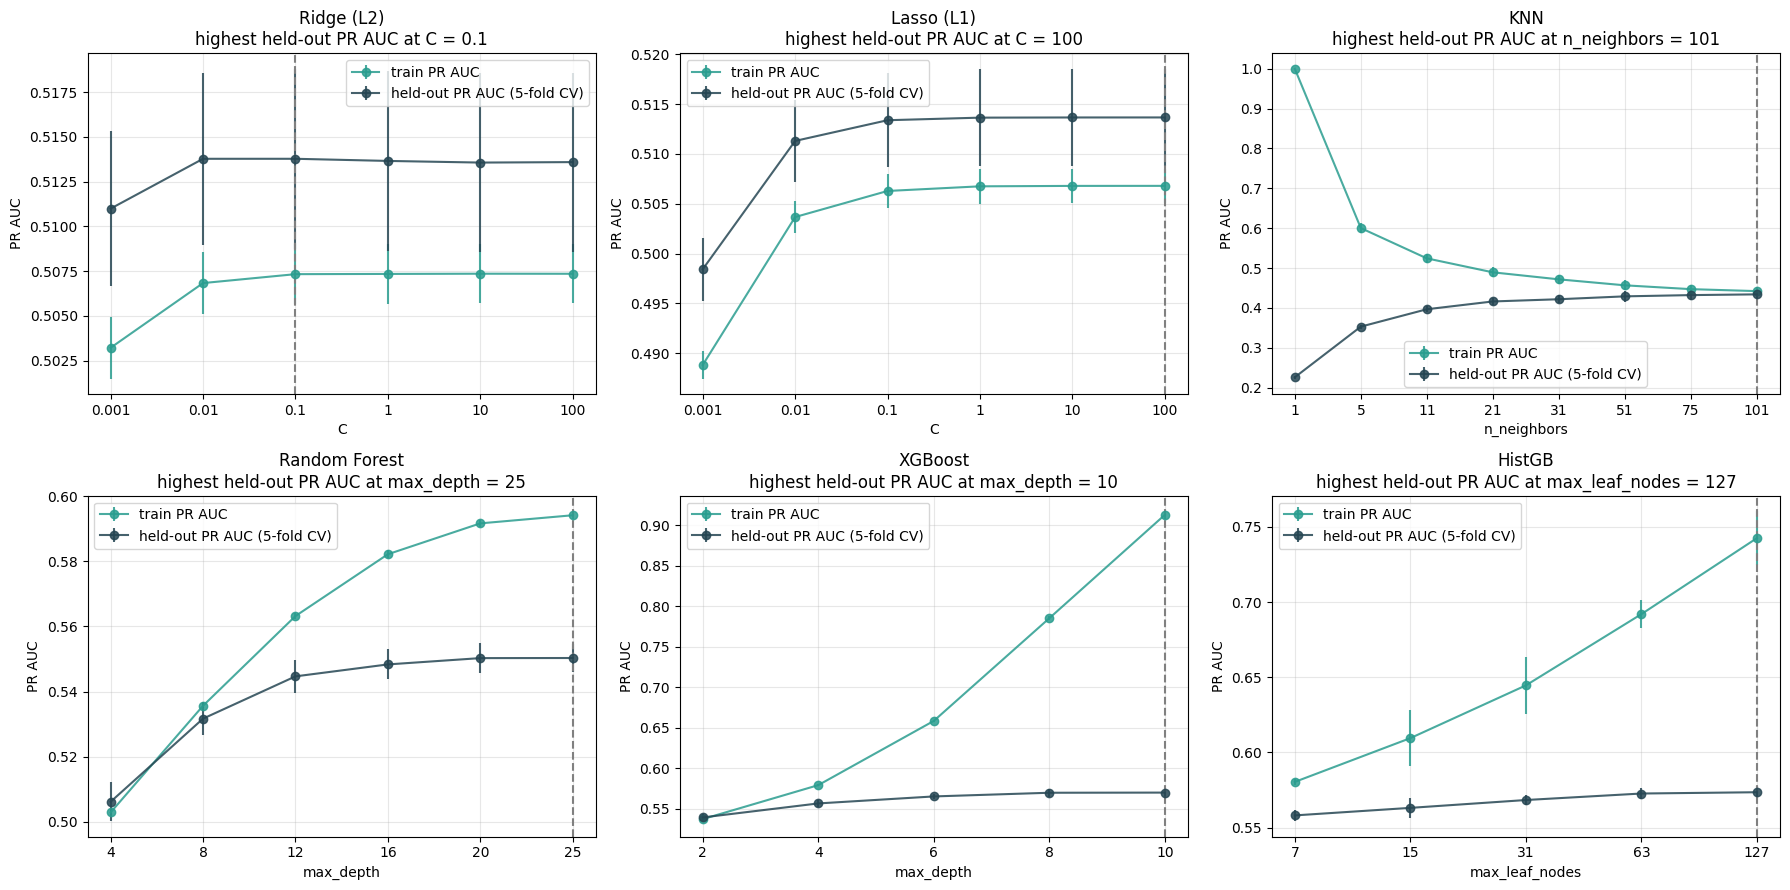

Logistic Reg (no penalty, nothing to tune): train PR AUC = 0.5074, held-out PR AUC = 0.5136 ± 0.0050


In [16]:
# Train vs held-out PR AUC for each hyperparameter value (mean ± 1 std over 5 folds)
tuned_algos = [a for a in TUNING_GRID if a != "logreg"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, algo in zip(axes.flat, tuned_algos):
    param, values = TUNING_GRID[algo]
    c = curves[algo]
    x = np.arange(len(values))   # equally spaced positions; tick labels show the real values
    ax.errorbar(x, c["train_mean"], yerr=c["train_std"], marker="o", label="train PR AUC", alpha=0.85)
    ax.errorbar(x, c["cv_mean"], yerr=c["cv_std"], marker="o", label="held-out PR AUC (5-fold CV)", alpha=0.85)
    best = int(c["cv_mean"].idxmax())
    ax.axvline(best, ls="--", color="grey")
    ax.set_xticks(x, [str(v) for v in values])
    ax.set_title(f"{MODEL_NAMES[algo]}\nhighest held-out PR AUC at {param} = {values[best]}")
    ax.set_xlabel(param); ax.set_ylabel("PR AUC"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

lr0 = curves["logreg"].iloc[0]
print(f"Logistic Reg (no penalty, nothing to tune): train PR AUC = {lr0.train_mean:.4f}, "
      f"held-out PR AUC = {lr0.cv_mean:.4f} ± {lr0.cv_std:.4f}")

**Observations: tuning**
- **Logistic Reg / Ridge / Lasso:** held-out PR AUC is flat at about 0.514 for every C ≥ 0.01, and train ≈ held-out. With 200k bids and about 200 columns there is little variance for a penalty to control, so regularisation neither helps nor hurts. Only a very strong L1 penalty (C = 0.001) removes useful signal (0.498).
- **KNN:** k = 1 memorises the training set (train 1.00 vs held-out 0.23). Held-out PR AUC rises with k and is still creeping up at k = 101 (0.434), but the gain after k ≈ 51 is under 0.005. KNN stays well below every other model.
- **Random Forest:** held-out PR AUC levels off from max_depth ≈ 16–20 (0.548–0.550) while train keeps rising. The gap stays moderate (0.044 at depth 25) because `min_samples_leaf=20` and `max_samples=0.3` already regularise each tree.
- **XGBoost:** held-out PR AUC improves only slightly beyond depth 6 (0.565 → 0.570), while train climbs from 0.66 to 0.91. Depth 10 is the CV best but has the largest train/held-out gap of any model (0.34). Depth 6 is the more conservative option, at a cost of about 0.005 held-out PR AUC.
- **HistGB:** same pattern at a smaller scale; going from 31 to 127 leaves gains 0.005 held-out PR AUC but doubles the gap (0.076 → 0.169). It is kept at **31 leaves**, the 02_D baseline setting, so scenario 1 reproduces the earlier result.

In the table below, *Selected* defaults to the CV-best value (except HistGB). Any entry in `selected_params` can be changed to trade a little held-out PR AUC for a smaller train/held-out gap.

In [17]:
# ---- Chosen hyperparameter for each model (from the charts above) ----
# None = use the value with the highest held-out PR AUC; replace with a number to override.
# HistGB keeps 31 (the default) so it matches the 02_D_modeling baseline.
selected_params = {
    "ridge": None,     # C
    "lasso": None,     # C
    "knn":   None,     # n_neighbors
    "rf":    None,     # max_depth
    "xgb":   None,     # max_depth
    "hgb":   31,       # max_leaf_nodes
}

final_params, rows = {"logreg": {}}, []
for algo in tuned_algos:
    param, values = TUNING_GRID[algo]
    c = curves[algo].set_index("value")
    best_value = c["cv_mean"].idxmax()
    chosen = selected_params[algo] if selected_params[algo] is not None else best_value
    final_params[algo] = {param: chosen}
    r = c.loc[chosen]
    rows.append({"Model": MODEL_NAMES[algo], "Hyperparameter": param, "Best (CV)": best_value,
                 "Selected": chosen, "Mean Train PR AUC": r.train_mean, "Mean Held-out PR AUC": r.cv_mean,
                 "Held-out Std": r.cv_std, "Train-Held-out Gap": r.train_mean - r.cv_mean})
r = curves["logreg"].iloc[0]
rows.insert(0, {"Model": "Logistic Reg", "Hyperparameter": "-", "Best (CV)": "-", "Selected": "-",
                "Mean Train PR AUC": r.train_mean, "Mean Held-out PR AUC": r.cv_mean,
                "Held-out Std": r.cv_std, "Train-Held-out Gap": r.train_mean - r.cv_mean})
tuning_summary = pd.DataFrame(rows).set_index("Model")
display(tuning_summary.round(4))

,Hyperparameter,Best (CV),Selected,Mean Train PR AUC,Mean Held-out PR AUC,Held-out Std,Train-Held-out Gap
Model,,,,,,,
Logistic Reg,-,-,-,0.5074,0.5136,0.0050,-0.0062
Ridge (L2),C,0.1,0.1,0.5073,0.5138,0.0050,-0.0064
Lasso (L1),C,100.0,100.0,0.5068,0.5137,0.0049,-0.0069
KNN,n_neighbors,101,101,0.4421,0.4339,0.0118,0.0081
Random Forest,max_depth,25,25,0.5941,0.5503,0.0044,0.0438
XGBoost,max_depth,10,10,0.9126,0.5700,0.0061,0.3426
HistGB,max_leaf_nodes,127,31,0.6445,0.5683,0.0036,0.0762


## 9. Final models: 3 scenarios × 7 algorithms
Each model is refitted with its selected hyperparameter on the **full training set** of its scenario and evaluated **once** on that scenario's test set:

| Scenario | Training data | Test data |
|---|---|---|
| All features (unbalanced) | Random split, 1.28M bids, real 85/15 balance | Random split, 320k bids |
| Undersampling 60/40 | Same training bids, undersampled to 60/40 inside the pipeline | Same test set as above |
| Time-based split | Bids before 1 July 2025 | Bids from 1 July 2025 onwards |

- **KNN** is trained on a stratified 200k-bid sample in every scenario, because full-size KNN takes hours.
- **Train scores** are computed on a 200k-bid sample of the rows the classifier was trained on (20k for KNN), using the same cross-fitted encodings as in section 8. For the undersampled models, that means the 60/40 sample.
- **Class predictions** use a 0.5 probability threshold. Threshold choice is discussed in section 12.

In [18]:
SCENARIOS = {
    "All features (unbalanced)": dict(X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test, undersample=False),
    "Undersampling 60/40":       dict(X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test, undersample=True),
    "Time-based split":          dict(X_tr=X_train_t, y_tr=y_train_t, X_te=X_test_t, y_te=y_test_t, undersample=False),
}


def stratified_sample(X, y, n, seed=RANDOM_STATE):
    """Stratified subsample of at most n rows."""
    if len(X) <= n:
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=seed)
    return Xs, ys


def param_label(algo):
    return ", ".join(f"{k} = {v}" for k, v in final_params[algo].items()) or "no penalty"


results, test_proba, fitted = [], {}, {}
for scen, s in SCENARIOS.items():
    X_tr, y_tr = s["X_tr"][INPUT_COLUMNS], s["y_tr"]
    X_te, y_te = s["X_te"][INPUT_COLUMNS], s["y_te"]
    for algo in MODEL_NAMES:
        t0 = time.time()
        X_fit, y_fit = stratified_sample(X_tr, y_tr, KNN_FIT_N) if algo == "knn" else (X_tr, y_tr)
        model, Xt, yt = fit_pipeline(make_model(algo, final_params[algo], undersample=s["undersample"]),
                                     X_fit, y_fit)

        # Train score: a random sample of the rows the classifier was trained on (cross-fitted encodings);
        # test score: the full test set through the normal predict path
        n_s = min(len(yt), 20_000 if algo == "knn" else TRAIN_SCORE_N)
        idx = np.random.default_rng(RANDOM_STATE).choice(len(yt), n_s, replace=False)
        y_s = yt[idx]
        p_tr = model.steps[-1][1].predict_proba(take_rows(Xt, idx))[:, 1]
        p_te = model.predict_proba(X_te)[:, 1]
        del Xt
        pred = (p_te >= 0.5).astype(int)

        results.append({"Scenario": scen, "Model": MODEL_NAMES[algo], "Parameter": param_label(algo),
                        "Train PR AUC": average_precision_score(y_s, p_tr),
                        "Test PR AUC": average_precision_score(y_te, p_te),
                        "Train ROC AUC": roc_auc_score(y_s, p_tr), "Test ROC AUC": roc_auc_score(y_te, p_te),
                        "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred, zero_division=0),
                        "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred),
                        "Fit time (min)": (time.time() - t0) / 60})
        test_proba[(scen, algo)] = p_te
        if scen == "All features (unbalanced)":
            fitted[algo] = model          # keep scenario-1 models for feature importance
        print(f"{scen:27s} {MODEL_NAMES[algo]:13s} test PR AUC = {results[-1]['Test PR AUC']:.4f} "
              f"({results[-1]['Fit time (min)']:.1f} min)")

results = pd.DataFrame(results)

All features (unbalanced)   Logistic Reg  test PR AUC = 0.5769 (0.4 min)


All features (unbalanced)   Ridge (L2)    test PR AUC = 0.5769 (0.4 min)


All features (unbalanced)   Lasso (L1)    test PR AUC = 0.5764 (5.9 min)


All features (unbalanced)   KNN           test PR AUC = 0.5319 (6.4 min)


All features (unbalanced)   Random Forest test PR AUC = 0.6349 (1.0 min)


All features (unbalanced)   XGBoost       test PR AUC = 0.6580 (0.8 min)


... (11 outputs left out)

Time-based split            KNN           test PR AUC = 0.4450 (22.7 min)


Time-based split            Random Forest test PR AUC = 0.5886 (1.1 min)


Time-based split            XGBoost       test PR AUC = 0.5608 (0.8 min)


Time-based split            HistGB        test PR AUC = 0.5005 (0.8 min)


### 9.1 Summary of results
The main table follows the experiment grid: **test PR AUC**, with rows = scenarios and columns = algorithms. The detailed table below it adds train scores (to check for overfitting), ROC AUC, and accuracy / precision / recall / F1 for Failed/Cancelled at a 0.5 threshold.

In [19]:
order = list(MODEL_NAMES.values())
pivot = results.pivot(index="Scenario", columns="Model", values="Test PR AUC").loc[list(SCENARIOS), order]
print("Test PR AUC (positive class = Failed/Cancelled); no-skill baseline = failure rate "
      f"({y_test.mean():.3f} random split, {y_test_t.mean():.3f} time split)")
display(pivot.style.format("{:.4f}").highlight_max(axis=1, color="#cdeae6"))

pivot_roc = results.pivot(index="Scenario", columns="Model", values="Test ROC AUC").loc[list(SCENARIOS), order]
print("Test ROC AUC")
display(pivot_roc.style.format("{:.4f}").highlight_max(axis=1, color="#cdeae6"))

detail_cols = ["Parameter", "Train PR AUC", "Test PR AUC", "Train ROC AUC", "Test ROC AUC",
               "Accuracy", "Precision", "Recall", "F1", "Fit time (min)"]
display(results.set_index(["Scenario", "Model"])[detail_cols].round(4))

Test PR AUC (positive class = Failed/Cancelled); no-skill baseline = failure rate (0.151 random split, 0.198 time split)


Model,Logistic Reg,Ridge (L2),Lasso (L1),KNN,Random Forest,XGBoost,HistGB
Scenario,,,,,,,
All features (unbalanced),0.5769,0.5769,0.5764,0.5319,0.6349,0.6580,0.6358
Undersampling 60/40,0.5580,0.5580,0.5579,0.5102,0.6116,0.6365,0.6198
Time-based split,0.5068,0.5079,0.5166,0.4450,0.5886,0.5608,0.5005


Test ROC AUC


Model,Logistic Reg,Ridge (L2),Lasso (L1),KNN,Random Forest,XGBoost,HistGB
Scenario,,,,,,,
All features (unbalanced),0.8319,0.8320,0.8319,0.8144,0.8630,0.8691,0.8591
Undersampling 60/40,0.8340,0.8340,0.8341,0.8138,0.8550,0.8649,0.8569
Time-based split,0.7323,0.7337,0.7442,0.6732,0.8061,0.7933,0.6984


Parameter  Train PR AUC  Test PR AUC  Train ROC AUC  Test ROC AUC  Accuracy  Precision  Recall      F1  Fit time (min)
Scenario                  Model                                                                                                                                          
All features (unbalanced) Logistic Reg            no penalty        0.5718       0.5769         0.8305        0.8319    0.8797     0.7582  0.3022  0.4321          0.4167
                          Ridge (L2)                 C = 0.1        0.5718       0.5769         0.8305        0.8320    0.8797     0.7587  0.3021  0.4321          0.3887
                          Lasso (L1)               C = 100.0        0.5710       0.5764         0.8302        0.8319    0.8796     0.7587  0.3012  0.4312          5.9262
                          KNN              n_neighbors = 101        0.5478       0.5319         0.8312        0.8144    0.8740     0.8477  0.2048  0.3299          6.3671
                          Random Forest       max_depth = 25        0.6639       0.6349         0.8844        0.8630    0.8872     0.8527  0.3084  0.4530          1.0339
                          XGBoost             max_depth = 10        0.7416       0.6580         0.9081        0.8691    0.8925     0.8346  0.3624  0.5054          0.7649
                          HistGB         max_leaf_nodes = 31        0.6457       0.6358         0.8659        0.8591    0.8893     0.8386  0.3334  0.4771          0.8764
Undersampling 60/40       Logistic Reg            no penalty        0.7805       0.5580         0.8306        0.8340    0.8175     0.4287  0.6148  0.5051          0.2356
                          Ridge (L2)                 C = 0.1        0.7805       0.5580         0.8306        0.8340    0.8175     0.4286  0.6146  0.5050          0.2376
                          Lasso (L1)               C = 100.0        0.7805       0.5579         0.8306        0.8341    0.8176     0.4288  0.6145  0.5051          2.3515
                          KNN              n_neighbors = 101        0.7443       0.5102         0.8124        0.8138    0.8300     0.4473  0.5176  0.4799          2.2206
                          Random Forest       max_depth = 25        0.8311       0.6116         0.8691        0.8550    0.8268     0.4504  0.6499  0.5321          0.4645
                          XGBoost             max_depth = 10        0.8953       0.6365         0.9166        0.8649    0.8343     0.4673  0.6689  0.5502          0.4233
                          HistGB         max_leaf_nodes = 31        0.8297       0.6198         0.8653        0.8569    0.8279     0.4531  0.6564  0.5361          0.5835
Time-based split          Logistic Reg            no penalty        0.5575       0.5068         0.8293        0.7323    0.8315     0.7519  0.2233  0.3444          0.6297
                          Ridge (L2)                 C = 0.1        0.5575       0.5079         0.8292        0.7337    0.8318     0.7518  0.2252  0.3466          0.5913
                          Lasso (L1)               C = 100.0        0.5576       0.5166         0.8293        0.7442    0.8327     0.7498  0.2332  0.3558          7.5680
                          KNN              n_neighbors = 101        0.5332       0.4450         0.8327        0.6732    0.8230     0.8037  0.1413  0.2403         22.7076
                          Random Forest       max_depth = 25        0.6530       0.5886         0.8855        0.8061    0.8411     0.8408  0.2441  0.3784          1.0646
                          XGBoost             max_depth = 10        0.7333       0.5608         0.9084        0.7933    0.8284     0.6113  0.3680  0.4595          0.8487
                          HistGB         max_leaf_nodes = 31        0.6252       0.5005         0.8615        0.6984    0.8334     0.7867  0.2185  0.3420          0.8445

**Observations: results**
- **Random split (main scenario):** the tree ensembles clearly beat the linear models and KNN. **XGBoost is best** (test PR AUC 0.658, ROC AUC 0.869), ahead of HistGB (0.636, which reproduces the 02_D baseline of 0.635) and Random Forest (0.635). The three logistic regressions are practically identical (0.577), confirming that the penalty does not matter at this sample size. KNN is lowest (0.532). Every model is far above the no-skill PR AUC of 0.151.
- **Overfitting check:** the linear models have train ≈ test. XGBoost has the largest gap (0.742 vs 0.658) but also the best test score, so its extra capacity still generalises.
- **Undersampling 60/40:** test PR AUC falls slightly for every model (XGBoost 0.658 → 0.637, HistGB 0.636 → 0.620), and ROC AUC barely moves. The ability to *rank* risky bids is unchanged. What changes is the probability scale: at the 0.5 threshold XGBoost's recall rises from 0.36 to 0.67 while precision falls from 0.83 to 0.47. The same trade-off is available by lowering the threshold of the unbalanced model (section 12.4), without discarding training data. (Train PR AUC in this scenario is measured on the 60/40 data, so it is inflated by the higher prevalence; see 9.4.)
- **Time-based split:** every model loses performance. XGBoost drops to 0.561 PR AUC / 0.793 ROC AUC, and HistGB falls the most (0.501). **Random Forest becomes the best model over time (0.589 / 0.806).** Two things change after July 2025: the failure rate rises from 14.2 % to 19.8 %, and the data combine PhilGEPS 1.5 and 2.0 exports, which label some categories differently. The random-split numbers are therefore an optimistic estimate of how a deployed model would perform.

### 9.2 Confusion matrices (threshold 0.5)
Each cell shows the count and, in brackets, the share of the **true** class. So the diagonal is the recall for each class: Awarded (top left) and Failed/Cancelled (bottom right).

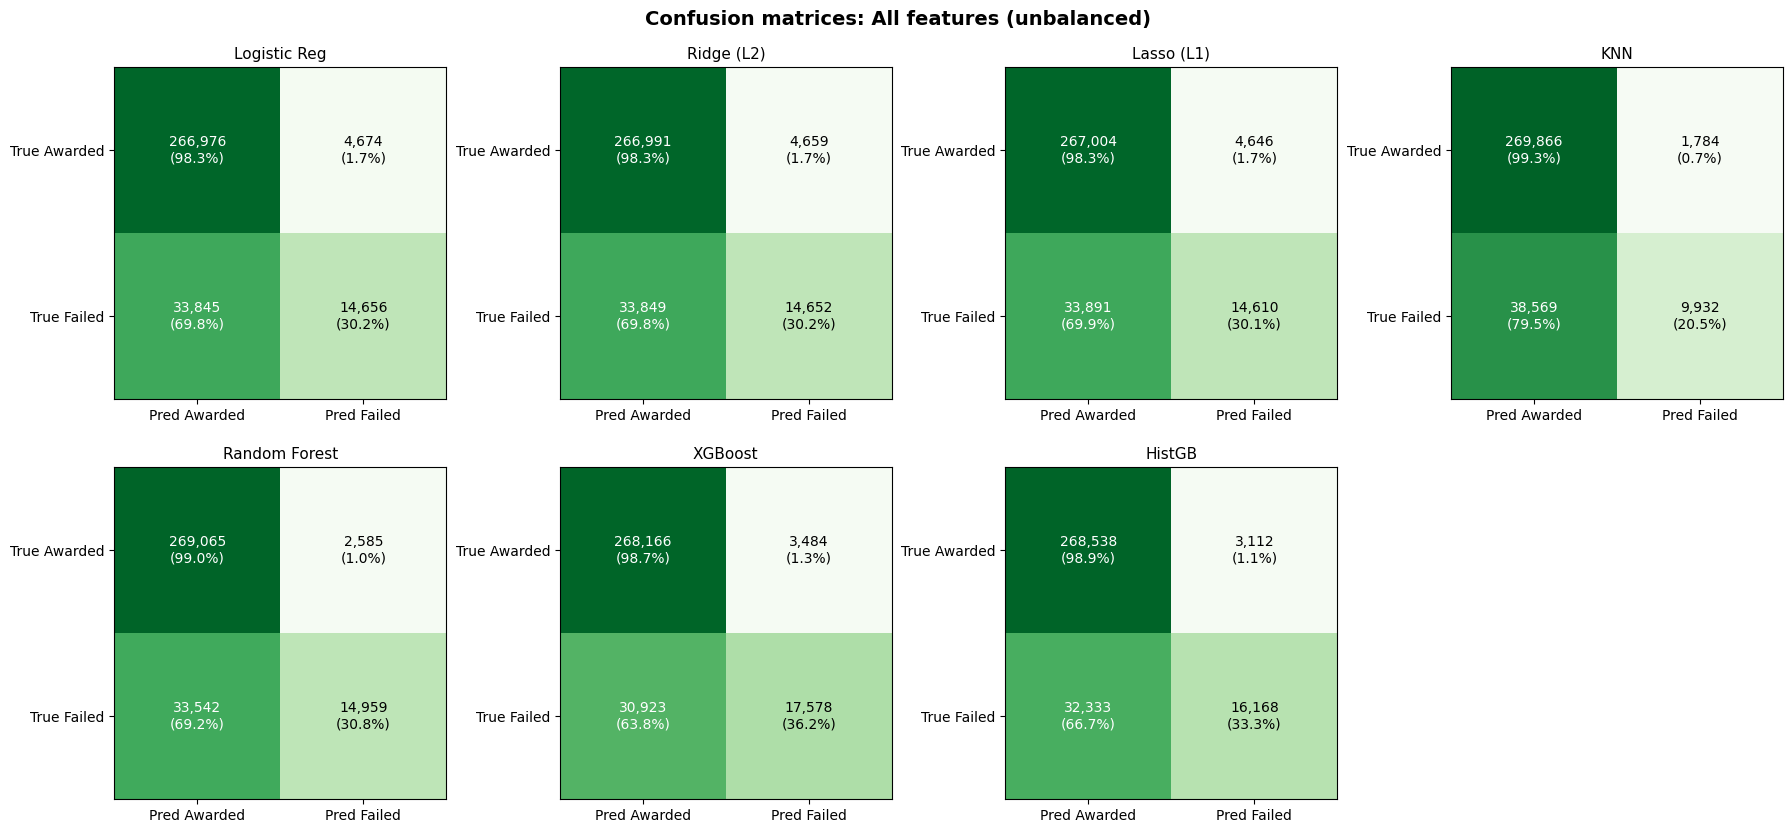

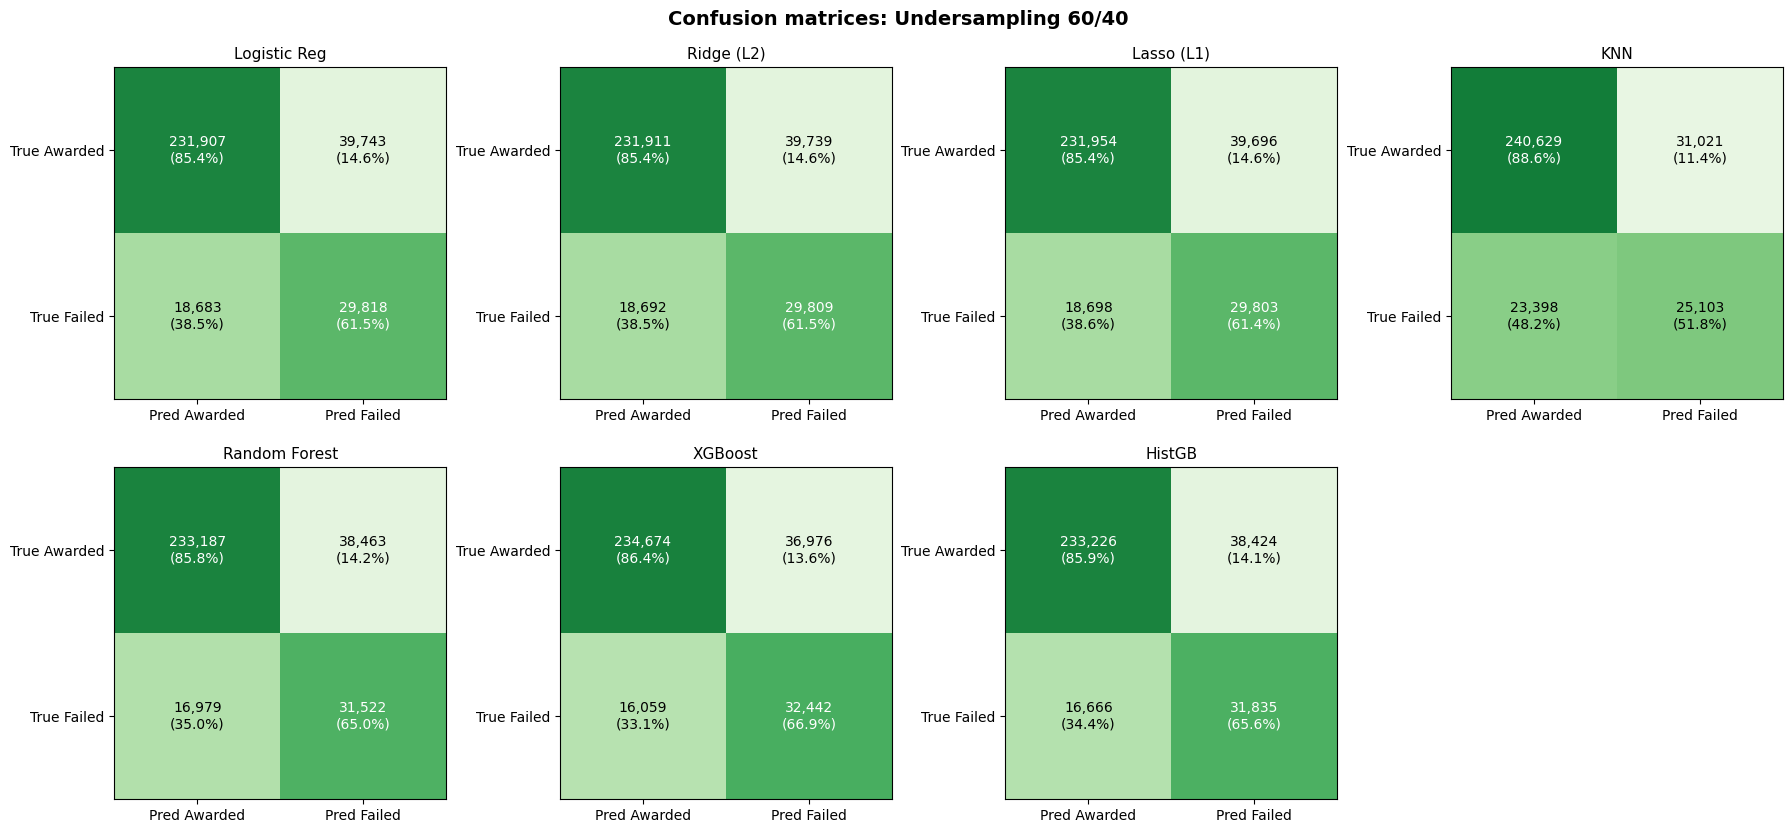

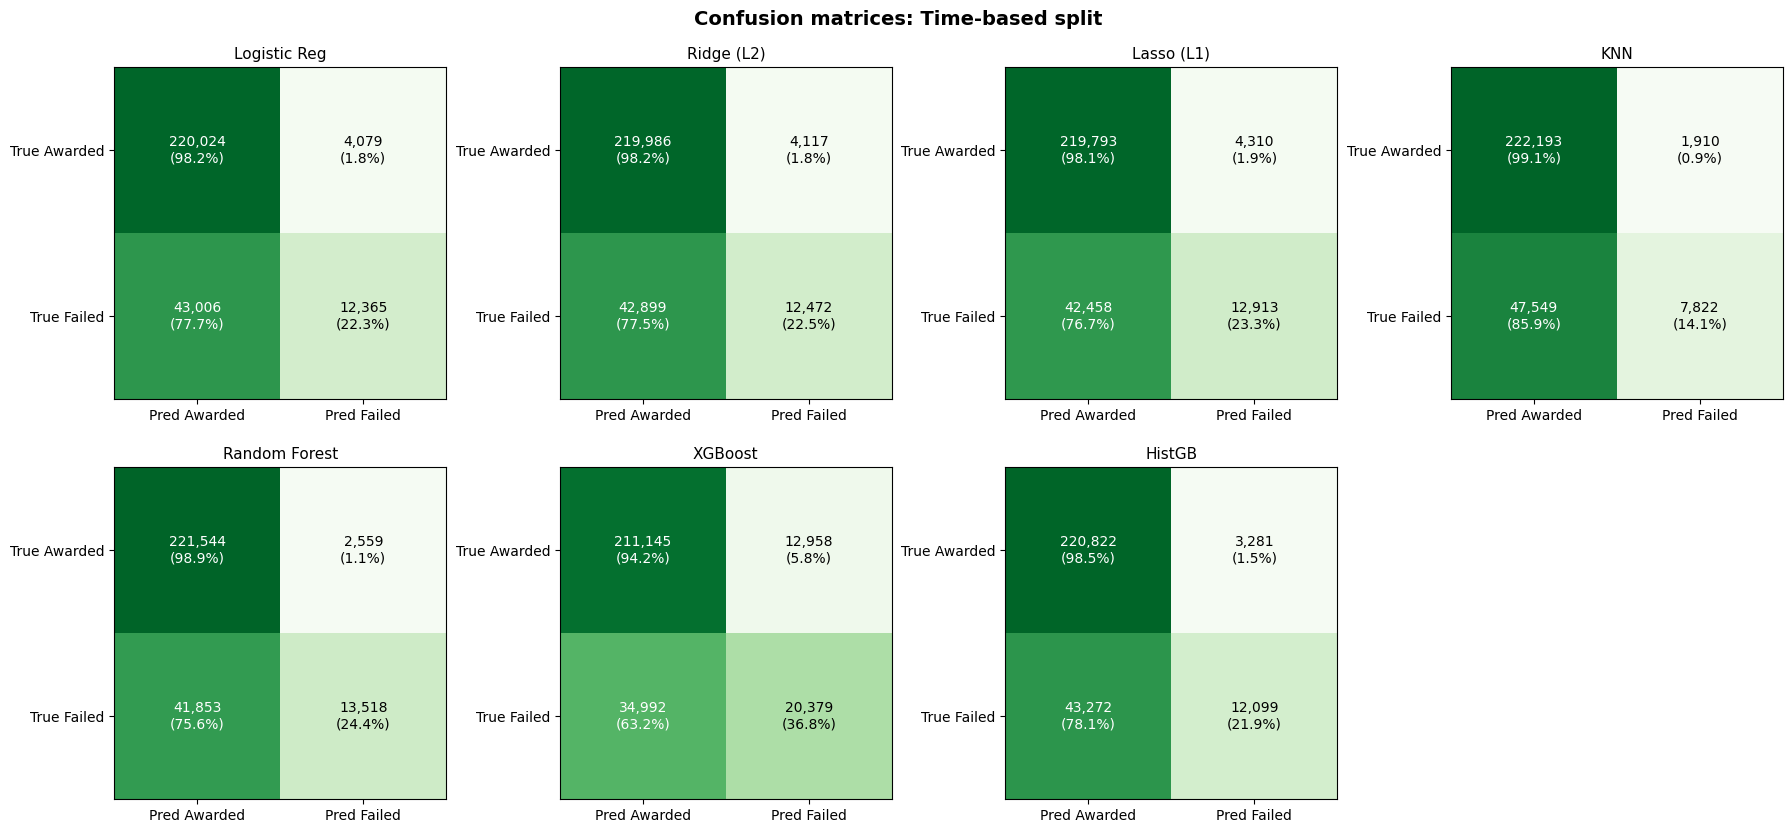

In [20]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Greens", vmin=0, vmax=1.1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({row_pct[i, j]:.1%})", ha="center", va="center", fontsize=10,
                    color="white" if row_pct[i, j] > 0.6 else "black")
    ax.set_xticks([0, 1], ["Pred Awarded", "Pred Failed"])
    ax.set_yticks([0, 1], ["True Awarded", "True Failed"])
    ax.set_title(title, fontsize=11)


for scen, s in SCENARIOS.items():
    fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
    for ax, algo in zip(axes.flat, MODEL_NAMES):
        pred = (test_proba[(scen, algo)] >= 0.5).astype(int)
        plot_cm(ax, s["y_te"], pred, MODEL_NAMES[algo])
    axes.flat[-1].axis("off")
    fig.suptitle(f"Confusion matrices: {scen}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 9.3 ROC and precision-recall curves
These curves show performance at **every** threshold, not just 0.5. On the PR curve, the dashed line is a no-skill model (precision equal to the failure rate).

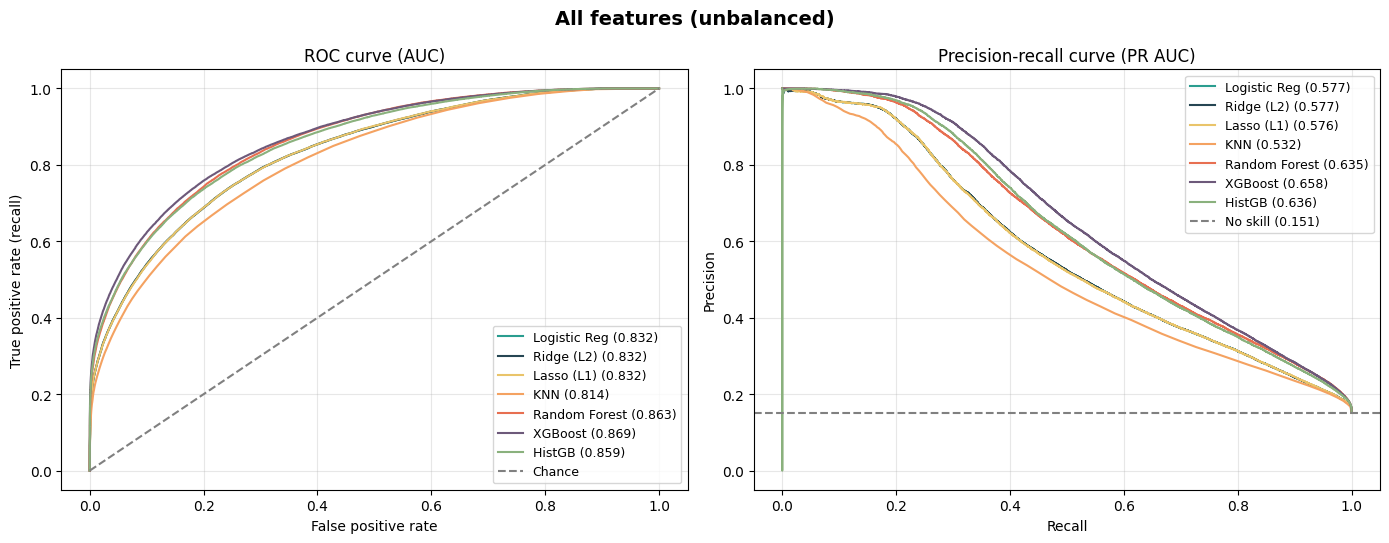

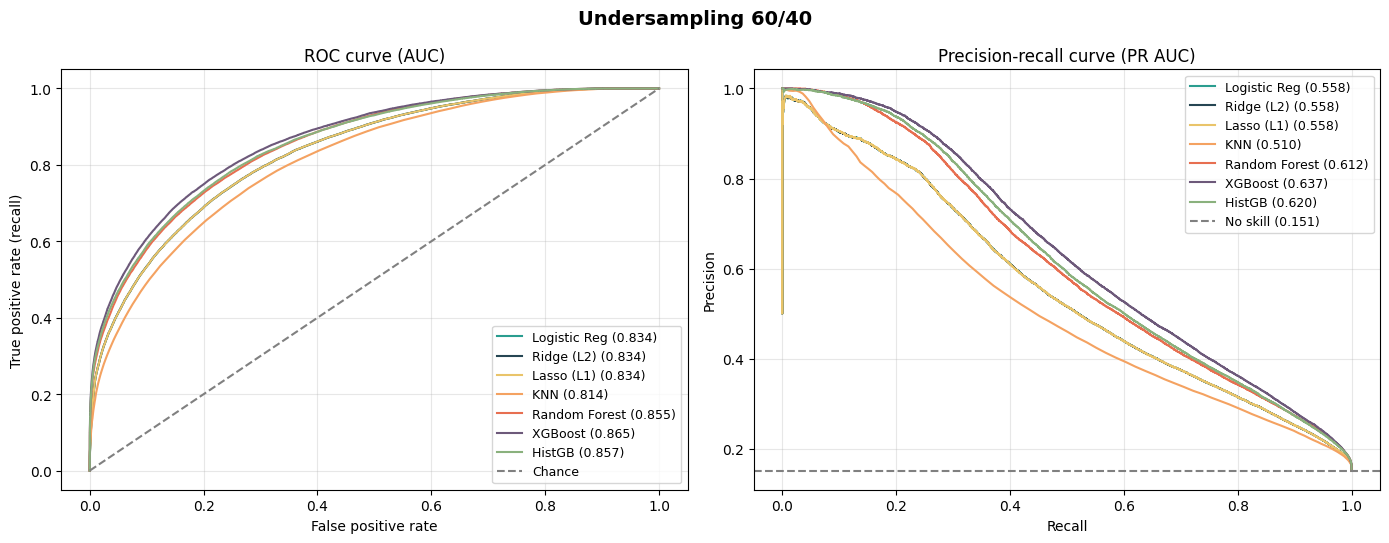

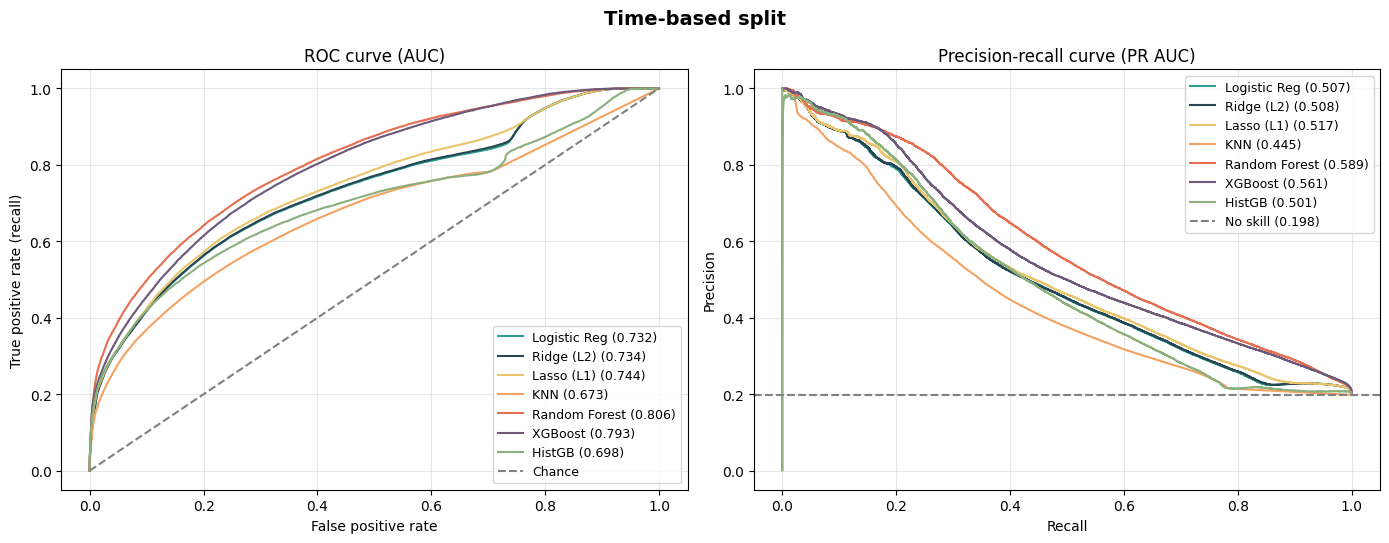

In [21]:
for scen, s in SCENARIOS.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    y_te = s["y_te"]
    for i, algo in enumerate(MODEL_NAMES):
        p = test_proba[(scen, algo)]
        fpr, tpr, _ = roc_curve(y_te, p)
        prec, rec, _ = precision_recall_curve(y_te, p)
        axes[0].plot(fpr, tpr, color=palette_D[i], label=f"{MODEL_NAMES[algo]} ({roc_auc_score(y_te, p):.3f})")
        axes[1].plot(rec, prec, color=palette_D[i], label=f"{MODEL_NAMES[algo]} ({average_precision_score(y_te, p):.3f})")
    axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="Chance")
    axes[1].axhline(y_te.mean(), ls="--", color="grey", label=f"No skill ({y_te.mean():.3f})")
    axes[0].set(title="ROC curve (AUC)", xlabel="False positive rate", ylabel="True positive rate (recall)")
    axes[1].set(title="Precision-recall curve (PR AUC)", xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=9)
    fig.suptitle(scen, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 9.4 Overfitting check: train vs test PR AUC
A large gap between train and test PR AUC means the model memorised the training data.

For the **undersampled** models, the train PR AUC is measured on the 60/40 training sample. PR AUC rises with the share of positives (a no-skill model scores 0.40 there instead of 0.15), so their train bars are naturally higher. For those models, compare train and test **ROC AUC** in the table above instead, because ROC AUC doesn't depend on the class balance.

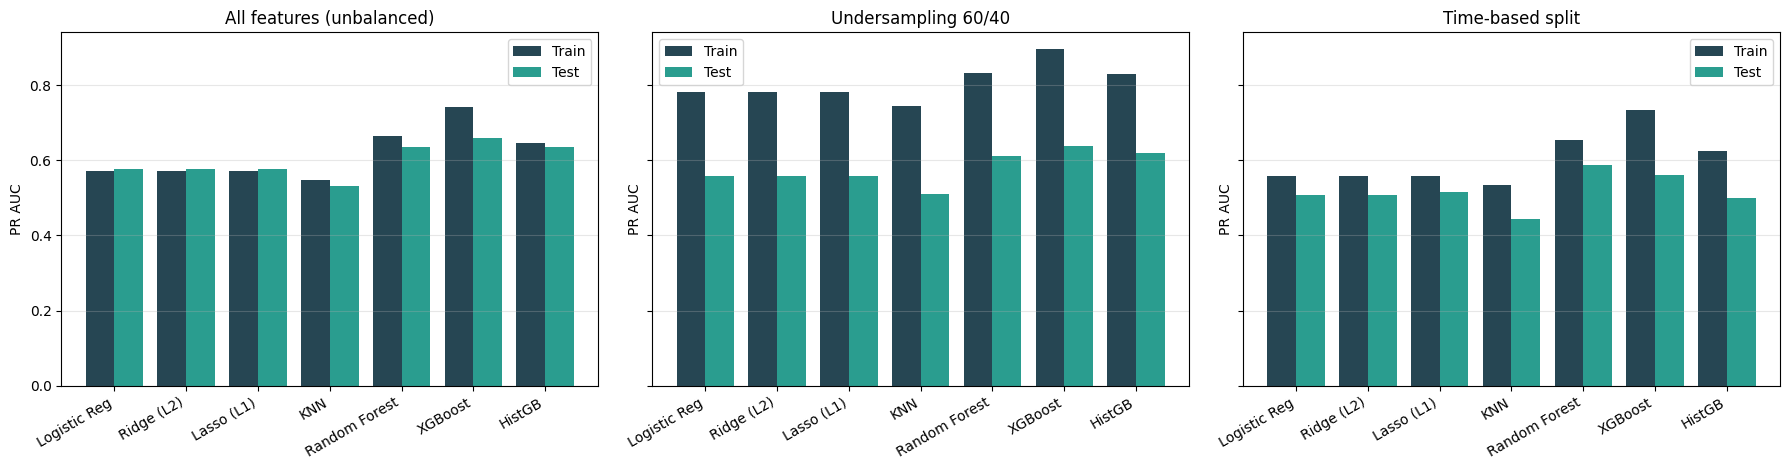

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, scen in zip(axes, SCENARIOS):
    r = results[results["Scenario"] == scen].set_index("Model").loc[order]
    x = np.arange(len(order))
    ax.bar(x - 0.2, r["Train PR AUC"], 0.4, label="Train", color=palette_D[1])
    ax.bar(x + 0.2, r["Test PR AUC"], 0.4, label="Test", color=palette_D[0])
    ax.set_xticks(x, order, rotation=30, ha="right")
    ax.set_title(scen); ax.set_ylabel("PR AUC"); ax.grid(axis="y", alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

## 10. Feature importance
Importance is measured three ways:
1. **Permutation importance (all models, comparable):** shuffle one raw input column and measure how much the test PR AUC drops. It works the same way for every algorithm and is measured on the **original columns**. Each column's effect includes every feature built from it (e.g. `Published Date` → bid window, month, Q4). Computed for the scenario-1 models on 50k test bids, 3 repeats. KNN uses 5k bids because its predictions are slow.
2. **Coefficients (Ridge, Lasso):** effect per one standard deviation, on the encoded features.
3. **Built-in importances (Random Forest, XGBoost):** how much each encoded feature improves the tree splits.

Logistic Reg  done (87s)


Ridge (L2)    done (118s)


Lasso (L1)    done (80s)


KNN           done (374s)


Random Forest done (40s)


XGBoost       done (40s)


HistGB        done (50s)


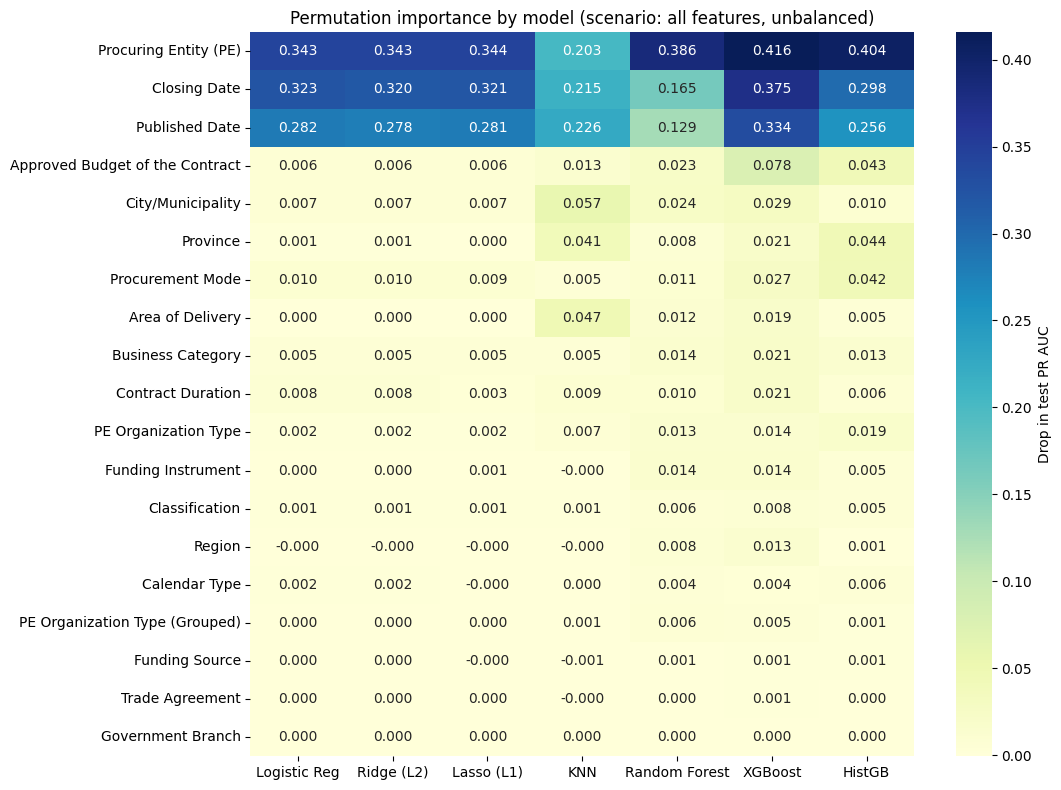

In [23]:
X_imp, y_imp = stratified_sample(X_test[INPUT_COLUMNS], y_test, IMPORTANCE_N)
X_imp_knn, y_imp_knn = stratified_sample(X_imp, y_imp, 5_000)

perm, perm_std = {}, {}
for algo, model in fitted.items():
    t0 = time.time()
    Xi, yi = (X_imp_knn, y_imp_knn) if algo == "knn" else (X_imp, y_imp)
    r = permutation_importance(model, Xi, yi, scoring="average_precision", n_repeats=3,
                               random_state=RANDOM_STATE, n_jobs=1)
    perm[MODEL_NAMES[algo]] = pd.Series(r.importances_mean, index=Xi.columns)
    perm_std[MODEL_NAMES[algo]] = pd.Series(r.importances_std, index=Xi.columns)
    print(f"{MODEL_NAMES[algo]:13s} done ({time.time() - t0:.0f}s)")

perm = pd.DataFrame(perm)[order]
perm_std = pd.DataFrame(perm_std)[order]
perm = perm.loc[perm.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(11, 8))
sns.heatmap(perm, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "Drop in test PR AUC"})
plt.title("Permutation importance by model (scenario: all features, unbalanced)")
plt.tight_layout()
plt.show()

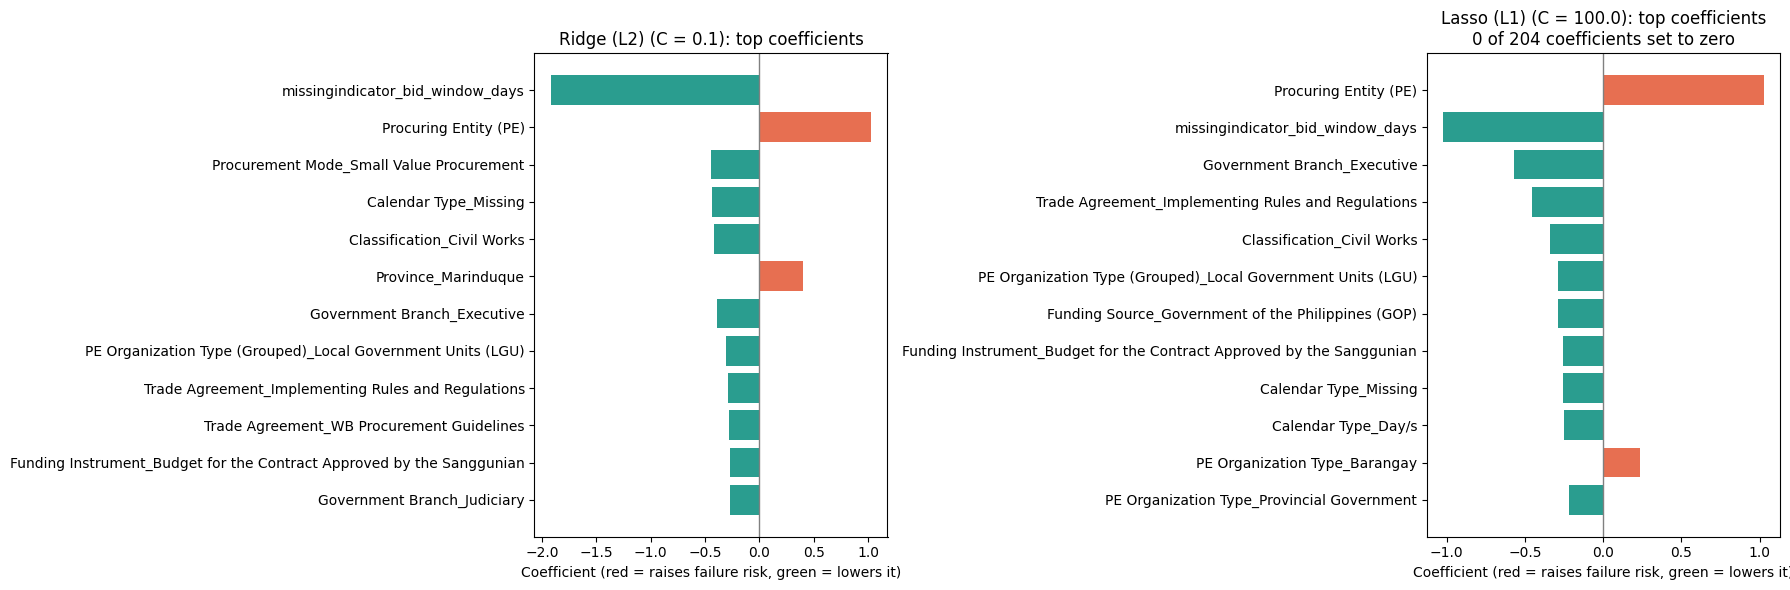

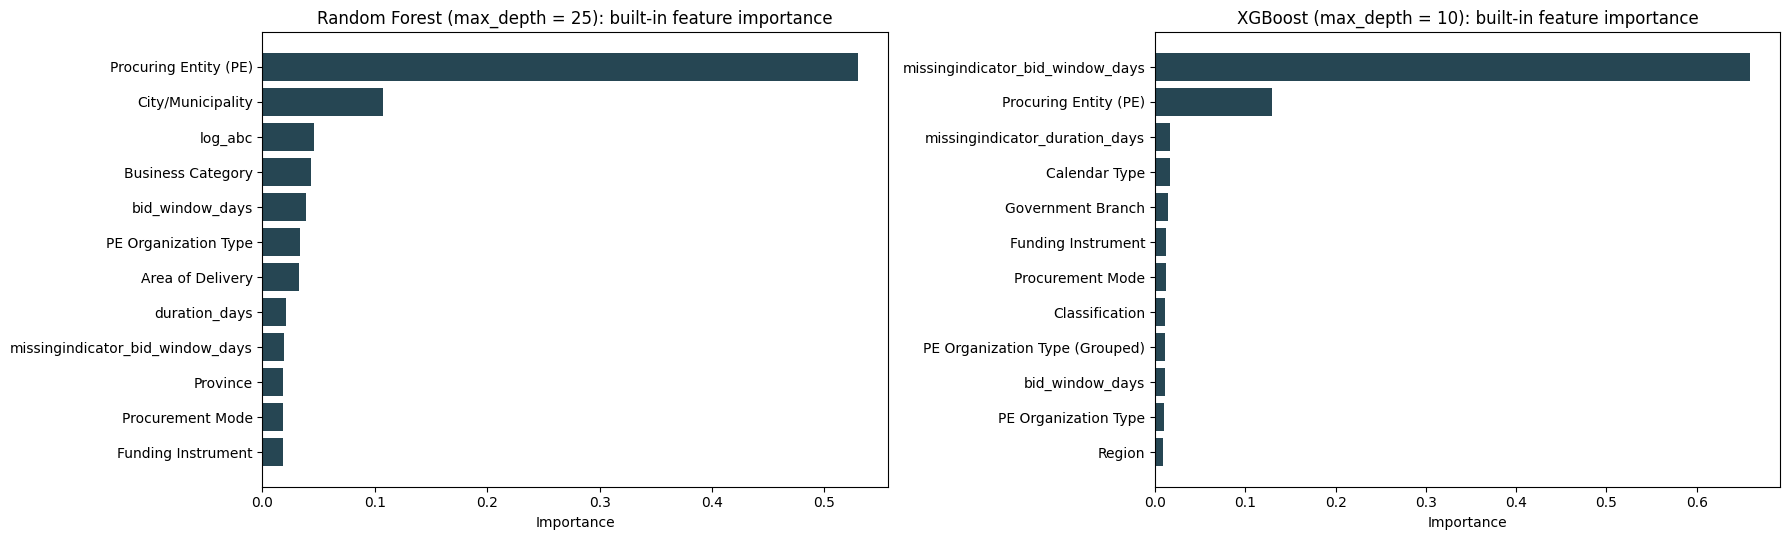

In [24]:
# Standardised coefficients of the penalised logistic regressions (top 12 in absolute value)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, algo in zip(axes, ["ridge", "lasso"]):
    names = fitted[algo].named_steps["preprocess"].get_feature_names_out()
    coef = pd.Series(fitted[algo].named_steps["clf"].coef_[0], index=names)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index[:12])[::-1]
    ax.barh(top.index, top.values, color=[palette_D[4] if v > 0 else palette_D[0] for v in top.values])
    ax.axvline(0, color="grey", lw=1)
    n_zero = int((coef == 0).sum())
    ax.set_title(f"{MODEL_NAMES[algo]} ({param_label(algo)}): top coefficients"
                 + (f"\n{n_zero} of {len(coef)} coefficients set to zero" if algo == "lasso" else ""))
    ax.set_xlabel("Coefficient (red = raises failure risk, green = lowers it)")
plt.tight_layout()
plt.show()

# Built-in importances of the tree ensembles (top 12)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, algo in zip(axes, ["rf", "xgb"]):
    names = fitted[algo].named_steps["preprocess"].get_feature_names_out()
    imp = pd.Series(fitted[algo].named_steps["clf"].feature_importances_, index=names)
    top = imp.sort_values(ascending=False)[:12][::-1]
    ax.barh(top.index, top.values, color=palette_D[1])
    ax.set_title(f"{MODEL_NAMES[algo]} ({param_label(algo)}): built-in feature importance")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

**Observations: feature importance**
- The **same three inputs dominate every model**: Procuring Entity (PE), Closing Date and Published Date. No other input reduces test PR AUC by more than 0.08 when shuffled.
- **Procuring Entity:** the entity's historical failure rate (target-encoded) is the strongest single predictor (0.34–0.42 for every model except KNN). Section 12.2(a) examines it.
- **Dates: read with caution.** The large values for the two date columns mostly reflect *missing* dates, not the calendar. About 6.6 % of training bids have no closing date, and practically none of them failed. These match the procurement modes with a 0 % failure rate in 12.2 (direct contracting, lease of real property, agency-to-agency, and so on), which have no bidding window. The models therefore learn "no bidding window → awarded". The largest Ridge coefficient and the second-largest Lasso coefficient is `missingindicator_bid_window_days`. Permutation importance shuffles one date column at a time, which makes *Closing − Published* negative (and therefore missing) for roughly half of the shuffled bids, so the model wrongly treats them as certain to be awarded. The drop in PR AUC therefore measures the value of a *consistent bidding window* and overstates the effect of the dates themselves. The calendar effect alone is small (month, 12.2 g).
- **Tree models also use** budget, location (Province, City/Municipality), Procurement Mode and Business Category. The linear models give these near-zero importance. Trees can model non-linear and interaction effects, which helps explain their advantage.
- **Lasso** chose a weak penalty (C = 100), so it sets **none** of the 204 coefficients to zero. Its coefficients agree with Ridge's.
- **KNN** spreads importance more evenly (location features matter more), because every scaled column contributes to the distance.

## 11. Best model
The best model is the one with the highest **test PR AUC** in the main scenario (all features, random split). The other scenarios show how it behaves with rebalancing and over time.

In [25]:
s1 = results[results["Scenario"] == "All features (unbalanced)"].set_index("Model")
best_name = s1["Test PR AUC"].idxmax()
best_algo = {v: k for k, v in MODEL_NAMES.items()}[best_name]
best_model = fitted[best_algo]
print(f"Best model: {best_name} ({param_label(best_algo)})")
display(results[results["Model"] == best_name].set_index("Scenario")[detail_cols].round(4))

Best model: XGBoost (max_depth = 10)


,Parameter,Train PR AUC,Test PR AUC,Train ROC AUC,Test ROC AUC,Accuracy,Precision,Recall,F1,Fit time (min)
Scenario,,,,,,,,,,
All features (unbalanced),max_depth = 10,0.7416,0.6580,0.9081,0.8691,0.8925,0.8346,0.3624,0.5054,0.7649
Undersampling 60/40,max_depth = 10,0.8953,0.6365,0.9166,0.8649,0.8343,0.4673,0.6689,0.5502,0.4233
Time-based split,max_depth = 10,0.7333,0.5608,0.9084,0.7933,0.8284,0.6113,0.3680,0.4595,0.8487


## 12. Deep dive: what drives procurement failure?
The analysis focuses on the best model's most important inputs, checks each one directly against observed failure rates, and then considers which probability threshold to use in practice.
### 12.1 Permutation importance of the best model

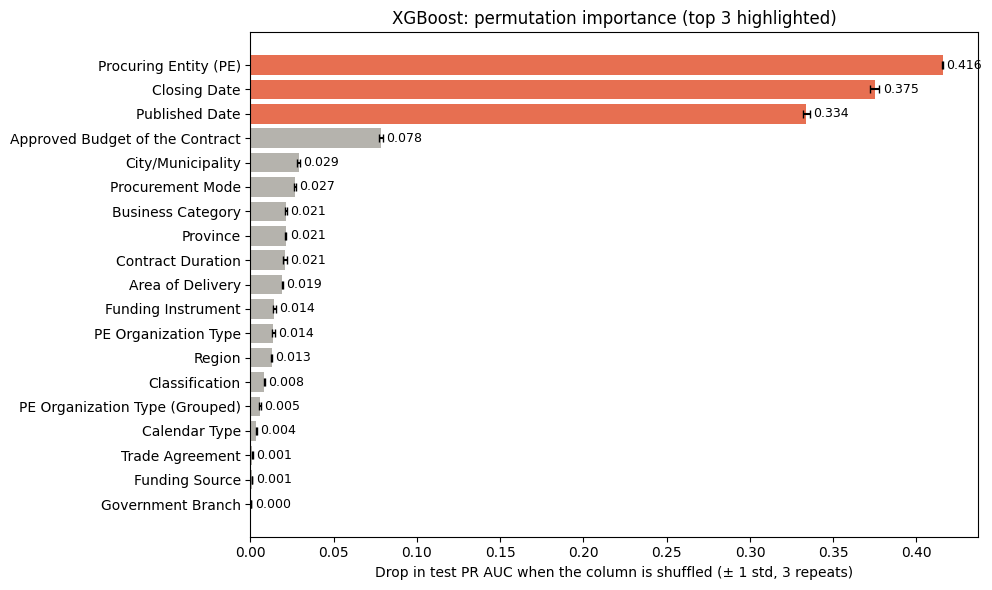

Top features: ['Procuring Entity (PE)', 'Closing Date', 'Published Date', 'Approved Budget of the Contract', 'City/Municipality', 'Procurement Mode', 'Business Category', 'Province']


In [26]:
imp_best = perm[best_name].sort_values()
err_best = perm_std[best_name].reindex(imp_best.index)
top_features = imp_best.index[::-1][:8].tolist()

fig, ax = plt.subplots(figsize=(10, 6))
colors = [palette_D[4] if f in top_features[:3] else "#b5b3ad" for f in imp_best.index]
ax.barh(imp_best.index, imp_best.values, xerr=err_best.values, color=colors, error_kw=dict(capsize=3))
for i, (v, e) in enumerate(zip(imp_best.values, err_best.values)):
    ax.text(v + e + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Drop in test PR AUC when the column is shuffled (± 1 std, 3 repeats)")
ax.set_title(f"{best_name}: permutation importance (top 3 highlighted)")
plt.tight_layout()
plt.show()
print("Top features:", top_features)

### 12.2 Failure rate by the main drivers
These plots use the **training bids**, with the same engineered features as the model. They show how the observed failure rate changes with each driver. They describe associations, not causes.

In [27]:
# Engineered view of the training bids (same transformations as the pipeline)
feat_train = ProcurementFeatures(CAT_FEATURES).transform(
    DropColumns(FEATURES_TO_REMOVE + LEAKY_FEATURES).transform(X_train[INPUT_COLUMNS]))
feat_train["failed"] = y_train.values
feat_train["abc"] = X_train["Approved Budget of the Contract"].values
overall = feat_train["failed"].mean()


def rate_plot(ax, table, title, xlabel="Failure rate", min_n=0):
    """Horizontal bars of failure rate with bid counts; dashed line = overall rate."""
    t = table[table["n"] >= min_n]
    bars = ax.barh(t.index.astype(str), t["rate"], color=palette_D[0])
    for b, (r, n) in zip(bars, t[["rate", "n"]].to_numpy()):
        ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2, f"{r:.0%} (n={int(n):,})", va="center", fontsize=8)
    ax.axvline(overall, ls="--", color=palette_D[4], label=f"overall {overall:.1%}")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.legend(loc="lower right")
    ax.set_xlim(0, min(1, t["rate"].max() * 1.35))


def rate_table(key):
    return feat_train.groupby(key, observed=True)["failed"].agg(rate="mean", n="size")

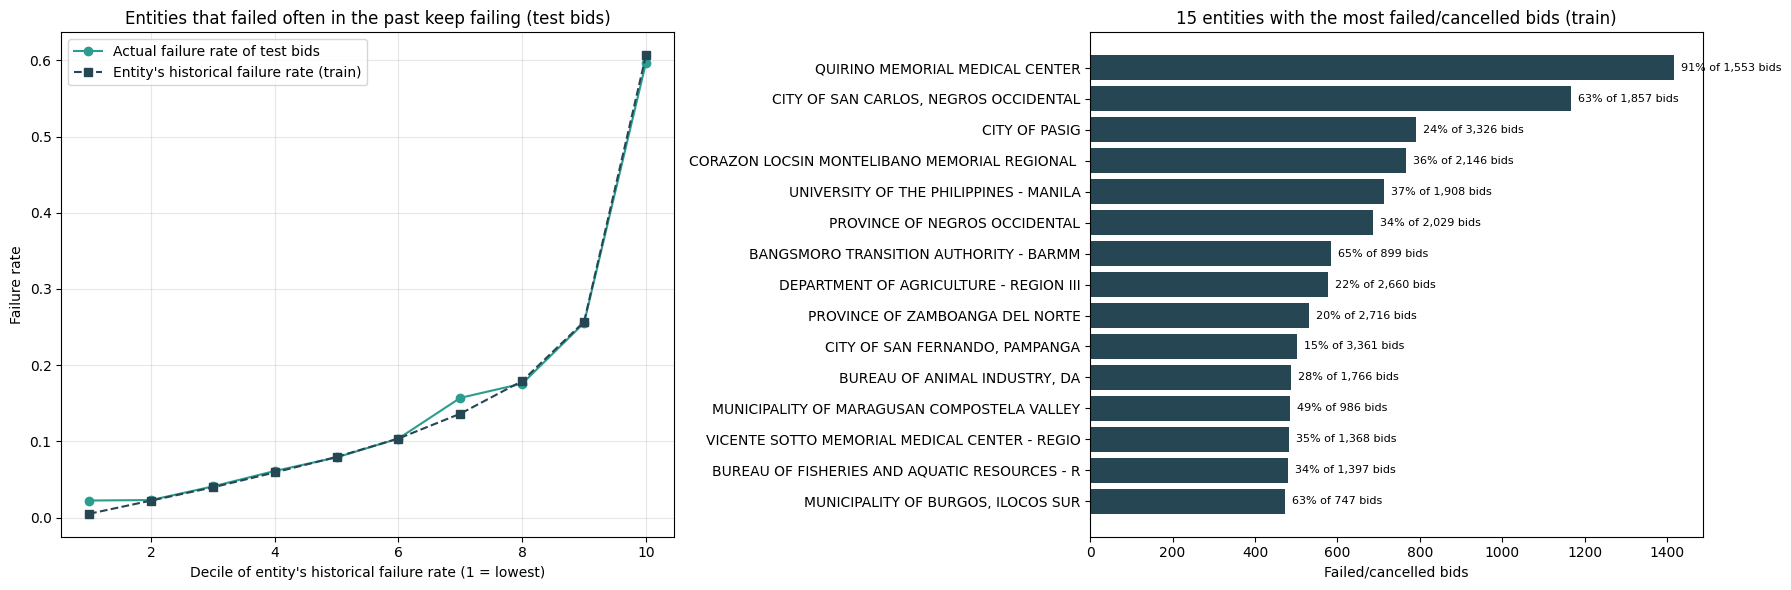

,pred,actual,n
decile,,,
1,0.005,0.022,32143
2,0.022,0.023,31964
3,0.040,0.041,32031
4,0.059,0.061,31988
5,0.080,0.079,32374
6,0.104,0.104,31593
7,0.136,0.157,32152
8,0.179,0.176,31921
9,0.257,0.256,31988


In [28]:
# (a) Procuring entity: does an entity's PAST failure rate predict its NEW bids' failures?
#     Target-encode the entity on the training bids, apply to the test bids, compare by decile.
te = TargetEncoder(target_type="binary", random_state=RANDOM_STATE).fit(
    X_train[["Procuring Entity (PE)"]].astype(str), y_train)
pe_rate_test = te.transform(X_test[["Procuring Entity (PE)"]].astype(str)).ravel()
pe_dec = pd.DataFrame({"pe_rate": pe_rate_test, "failed": y_test.values})
pe_dec["decile"] = pd.qcut(pe_dec["pe_rate"], 10, labels=False, duplicates="drop") + 1
dec = pe_dec.groupby("decile").agg(pred=("pe_rate", "mean"), actual=("failed", "mean"), n=("failed", "size"))

# (b) Entities with the most failed bids (training set)
pe = feat_train.groupby("Procuring Entity (PE)")["failed"].agg(failures="sum", n="size", rate="mean")
top_pe = pe.sort_values("failures", ascending=False).head(15)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].plot(dec.index, dec["actual"], marker="o", label="Actual failure rate of test bids")
axes[0].plot(dec.index, dec["pred"], marker="s", ls="--", label="Entity's historical failure rate (train)")
axes[0].set(xlabel="Decile of entity's historical failure rate (1 = lowest)", ylabel="Failure rate",
            title="Entities that failed often in the past keep failing (test bids)")
axes[0].grid(alpha=0.3); axes[0].legend()
bars = axes[1].barh([n[:45] for n in top_pe.index], top_pe["failures"], color=palette_D[1])
for b, (f, n, r) in zip(bars, top_pe[["failures", "n", "rate"]].to_numpy()):
    axes[1].text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {r:.0%} of {int(n):,} bids", va="center", fontsize=8)
axes[1].set(title="15 entities with the most failed/cancelled bids (train)", xlabel="Failed/cancelled bids")
plt.tight_layout()
plt.show()
display(dec.round(3))

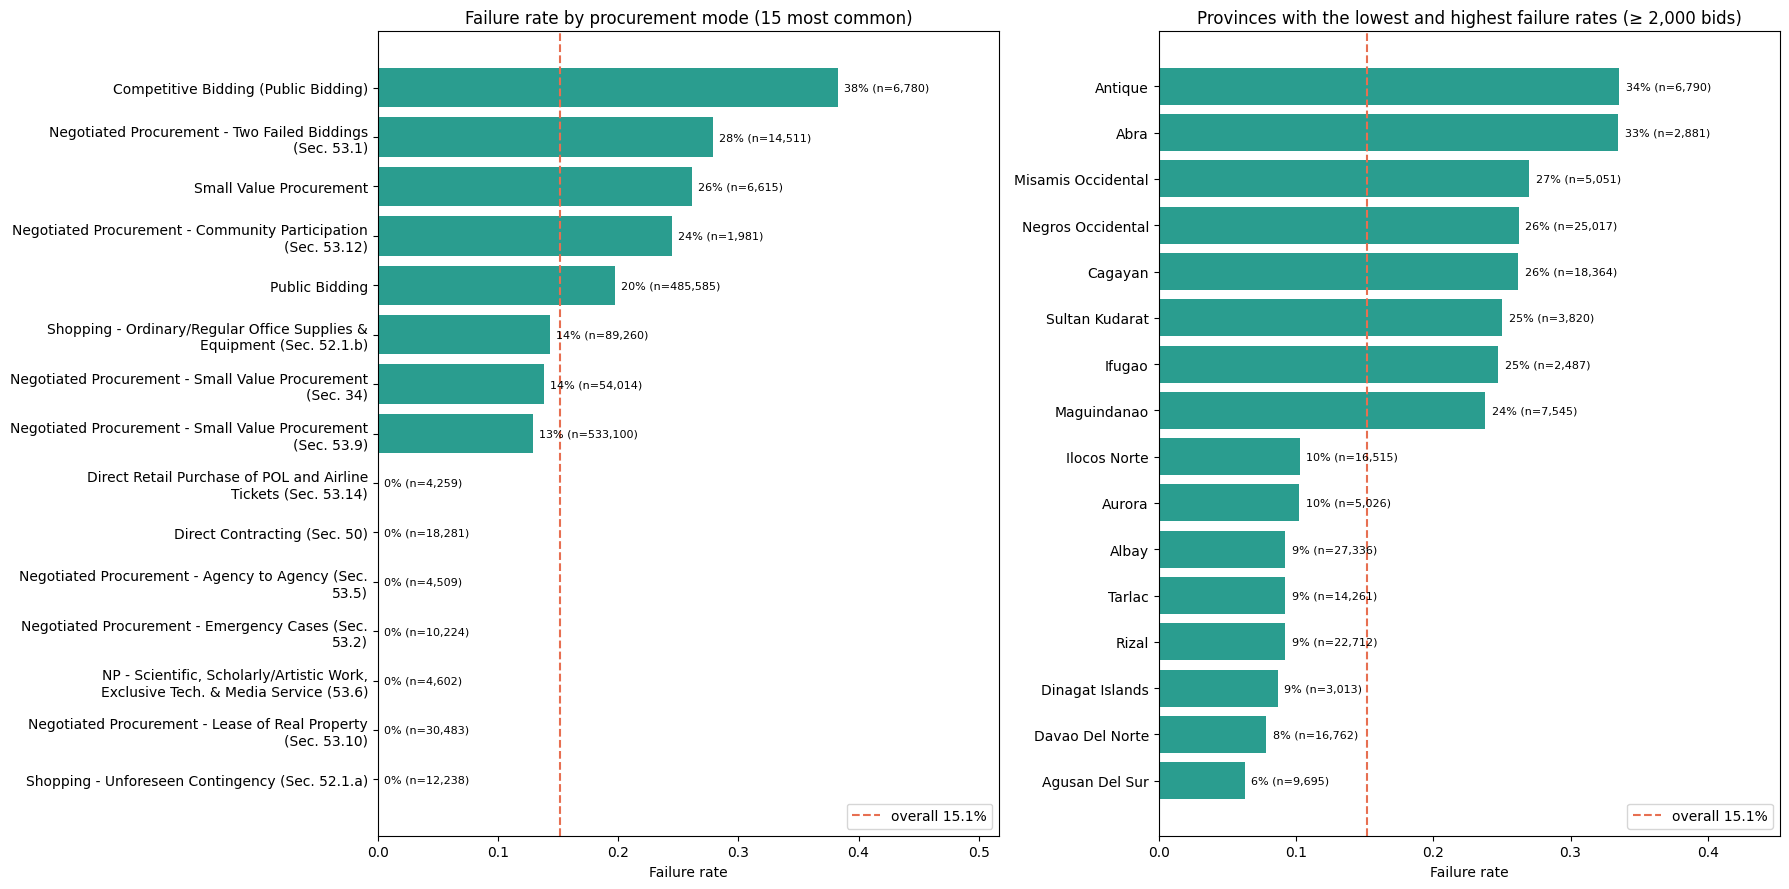

In [29]:
# (c) Procurement mode and (d) province
mode = rate_table("Procurement Mode").sort_values("n", ascending=False).head(15).sort_values("rate")
prov = rate_table("Province")
prov = prov[prov["n"] >= 2_000].sort_values("rate")
prov = pd.concat([prov.head(8), prov.tail(8)])

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
import textwrap
# Wrap (not cut) the long mode names: several share the same first 55 characters
rate_plot(axes[0], mode.rename(index=lambda s: textwrap.fill(s, 48)), "Failure rate by procurement mode (15 most common)")
rate_plot(axes[1], prov, "Provinces with the lowest and highest failure rates (≥ 2,000 bids)")
plt.tight_layout()
plt.show()

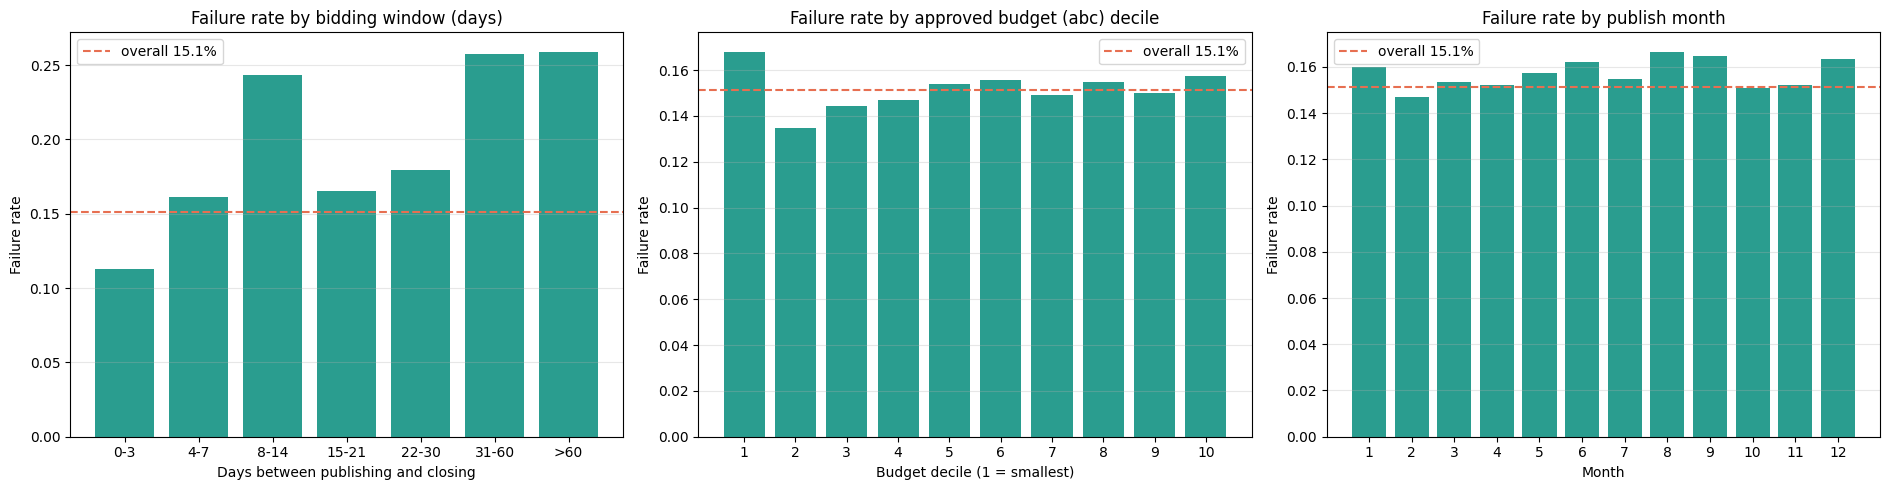

Median budget (PHP) per ABC decile:
 abc_decile
1         54,000
2         78,190
3        108,000
4        160,000
5        238,205
6        370,000
7        614,524
8      1,000,000
9      2,881,100
10    14,849,652


In [30]:
# (e) bidding window, (f) approved budget, (g) publish month
feat_train["window_bin"] = pd.cut(feat_train["bid_window_days"], [-1, 3, 7, 14, 21, 30, 60, np.inf],
                                  labels=["0-3", "4-7", "8-14", "15-21", "22-30", "31-60", ">60"])
feat_train["abc_decile"] = pd.qcut(feat_train["abc"].rank(method="first"), 10, labels=False) + 1
abc_edges = feat_train.groupby("abc_decile")["abc"].median()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, key, title, xl in [(axes[0], "window_bin", "Bidding window (days)", "Days between publishing and closing"),
                           (axes[1], "abc_decile", "Approved budget (ABC) decile", "Budget decile (1 = smallest)"),
                           (axes[2], "pub_month", "Publish month", "Month")]:
    t = rate_table(key)
    ax.bar(t.index.astype(str), t["rate"], color=palette_D[0])
    ax.axhline(overall, ls="--", color=palette_D[4], label=f"overall {overall:.1%}")
    ax.set_title(f"Failure rate by {title.lower()}"); ax.set_xlabel(xl); ax.set_ylabel("Failure rate")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    if key == "pub_month":
        ax.set_xticks(range(len(t)), [str(int(m)) for m in t.index])
plt.tight_layout()
plt.show()
print("Median budget (PHP) per ABC decile:\n", abc_edges.map("{:,.0f}".format).to_string())

### 12.3 Partial dependence: the model's view
Partial dependence shows how the best model's **predicted** failure probability changes as one engineered feature varies, with all the others held at their observed values. It complements the observed rates in 12.2. Computed on 5k training bids that have both dates and a contract duration (the grid cannot be built from missing values).

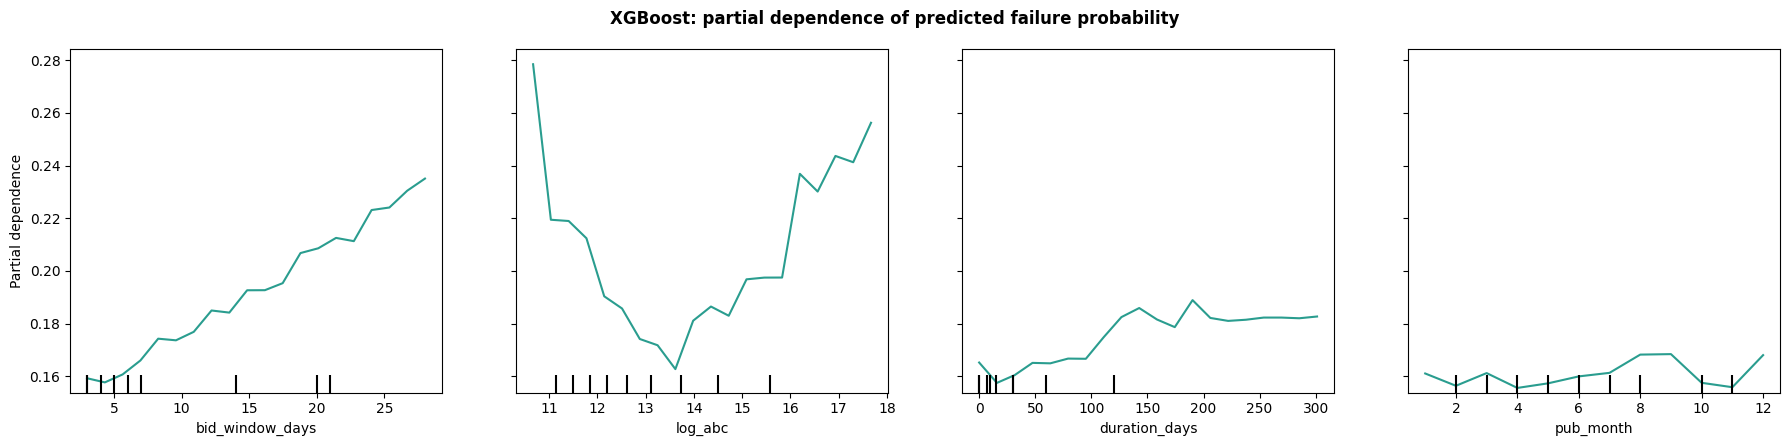

In [31]:
# Scenario-1 pipelines are: drop -> features -> preprocess -> clf, so [:2] builds features, [2:] predicts
pdp_features = ["bid_window_days", "log_abc", "duration_days", "pub_month"]
pd_X = best_model[:2].transform(X_train[INPUT_COLUMNS])                 # drop + features
# Partial dependence needs complete values to build its grid -> bids that have both dates and a duration
pd_X = pd_X.dropna(subset=pdp_features).sample(5_000, random_state=RANDOM_STATE)
pd_X["duration_days"] = pd_X["duration_days"].astype(float)            # nullable Float64 -> float
fig, ax = plt.subplots(figsize=(18, 4.5))
PartialDependenceDisplay.from_estimator(best_model[2:], pd_X, pdp_features, kind="average",
                                        grid_resolution=20, percentiles=(0.02, 0.98), ax=ax,
                                        n_cols=4, line_kw={"color": palette_D[0]})
fig.suptitle(f"{best_name}: partial dependence of predicted failure probability", fontweight="bold")
plt.tight_layout()
plt.show()

**Observations: drivers of failure (best model: XGBoost)**
- **(a) Procuring entity:** the entity's past failure rate predicts its new bids almost exactly. On test bids, the predicted vs actual failure rate per decile is 0.5 % vs 2.2 % in the lowest decile and 60.7 % vs 59.7 % in the highest. The riskiest 10 % of entities fail about 60 % of their bids, while the safest half fail fewer than 8 %. **An entity's track record is the single most useful signal.**
- **(c) Procurement mode:** "Competitive Bidding (Public Bidding)" fails most often (38 %), followed by *Negotiated – Two Failed Biddings* (28 %), *Small Value Procurement* (26 %) and *Public Bidding* (20 %). Re-procurements of items that already failed twice still fail more than a quarter of the time. Non-competitive modes (direct contracting, emergency cases, lease, agency-to-agency, unforeseen contingency) are essentially never failed.
- **(d) Province:** among provinces with at least 2,000 bids, failure rates range from 6 % (Agusan del Sur) and 8 % (Davao del Norte) to 33–34 % (Abra, Antique). That is a five-fold difference by location.
- **(e) Bidding window:** very short windows (0–3 days, 11 %) fail least, while 8–14 days (24 %) and over 30 days (≈ 26 %) fail most. The pattern is not monotonic. Longer windows are typical of competitive public bidding, so this mostly reflects the procurement mode rather than the window itself.
- **(f) Budget:** the observed failure rate is nearly flat across ABC deciles (13.5–16.8 %). The partial dependence plot is U-shaped, however: predicted risk is about 28 % for the smallest budgets (≈ PHP 30k), about 16 % around PHP 1M, and rises again to about 25 % for the largest contracts (≈ PHP 40M). Budget therefore matters *given* the entity and mode, even though its overall effect is weak.
- **(g) Publish month:** rates range only from 14.7 % to 16.6 %, and the partial dependence is nearly flat (≈ 0.16–0.17). There is **no meaningful year-end (Q4) rush effect**.
- **Partial dependence, bidding window:** holding everything else fixed, predicted risk rises steadily with a longer window, from about 16 % at 3–5 days to about 23 % at 28 days. This holds within the same entity and mode, so longer windows carry some risk of their own, beyond reflecting competitive bidding.
- **Partial dependence, contract duration:** risk rises gently from about 16 % for short contracts to about 18 % for contracts over 120 days, then levels off. This is a minor effect.

### 12.4 Choosing a decision threshold
The 0.5 threshold is arbitrary. A procurement office would choose it based on the cost of each kind of error:
- A **missed failure** means re-bidding and delays.
- A **false alarm** means reviewing a bid that would have been fine.

The table and chart show precision, recall and F1 across thresholds for the best model on the test set.

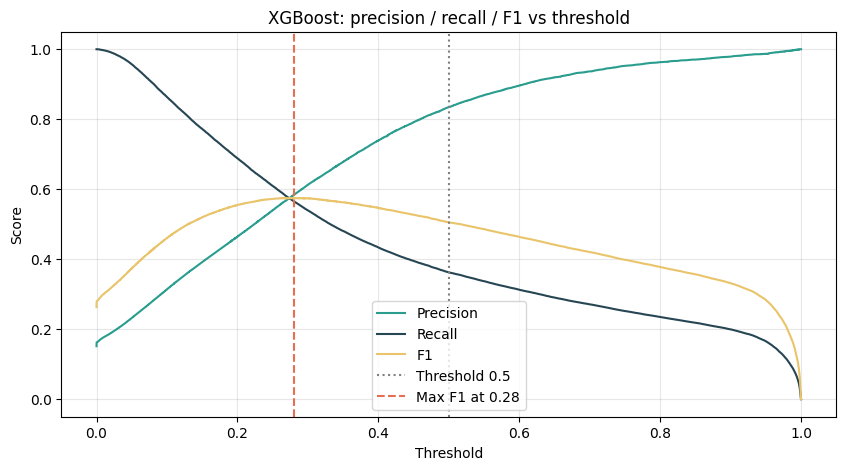

,Flagged bids,Precision,Recall,F1
Threshold,,,,
0.20,71882,0.464,0.688,0.555
0.28,47007,0.584,0.566,0.575
0.30,42730,0.613,0.540,0.574
0.40,28454,0.739,0.434,0.547
0.50,21062,0.835,0.362,0.505


In [32]:
p_best = test_proba[("All features (unbalanced)", best_algo)]
prec, rec, thr = precision_recall_curve(y_test, p_best)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_thr = thr[np.argmax(f1)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thr, prec[:-1], label="Precision")
ax.plot(thr, rec[:-1], label="Recall")
ax.plot(thr, f1, label="F1")
ax.axvline(0.5, ls=":", color="grey", label="Threshold 0.5")
ax.axvline(best_thr, ls="--", color=palette_D[4], label=f"Max F1 at {best_thr:.2f}")
ax.set(xlabel="Threshold", ylabel="Score", title=f"{best_name}: precision / recall / F1 vs threshold")
ax.grid(alpha=0.3); ax.legend()
plt.show()

rows = []
for t in sorted({0.2, 0.3, 0.4, 0.5, round(float(best_thr), 3)}):
    pr = (p_best >= t).astype(int)
    rows.append({"Threshold": t, "Flagged bids": int(pr.sum()), "Precision": precision_score(y_test, pr),
                 "Recall": recall_score(y_test, pr), "F1": f1_score(y_test, pr)})
display(pd.DataFrame(rows).set_index("Threshold").round(3))

### 12.5 Does the best model hold up over time?
The same algorithm and settings are compared on the random split and on the time-based split, where the model only learns from bids before July 2025.

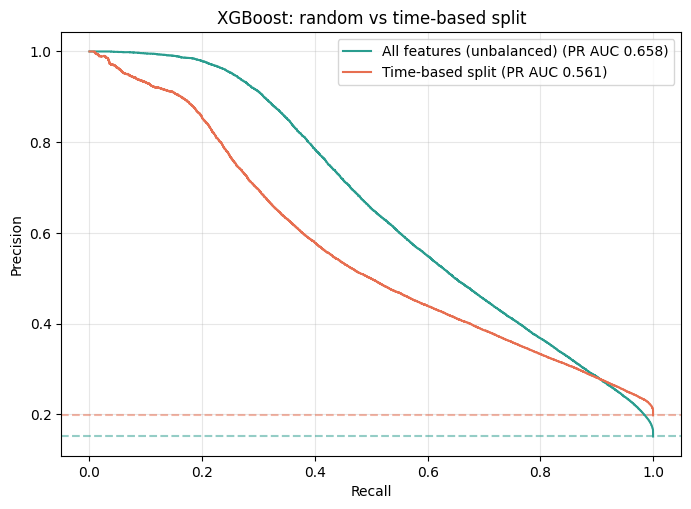

,Parameter,Train PR AUC,Test PR AUC,Train ROC AUC,Test ROC AUC,Accuracy,Precision,Recall,F1,Fit time (min)
Scenario,,,,,,,,,,
All features (unbalanced),max_depth = 10,0.7416,0.6580,0.9081,0.8691,0.8925,0.8346,0.3624,0.5054,0.7649
Time-based split,max_depth = 10,0.7333,0.5608,0.9084,0.7933,0.8284,0.6113,0.3680,0.4595,0.8487


In [33]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for scen, color in [("All features (unbalanced)", palette_D[0]), ("Time-based split", palette_D[4])]:
    y_te = SCENARIOS[scen]["y_te"]
    p = test_proba[(scen, best_algo)]
    prec_s, rec_s, _ = precision_recall_curve(y_te, p)
    ax.plot(rec_s, prec_s, color=color, label=f"{scen} (PR AUC {average_precision_score(y_te, p):.3f})")
    ax.axhline(y_te.mean(), ls="--", color=color, alpha=0.5)
ax.set(xlabel="Recall", ylabel="Precision", title=f"{best_name}: random vs time-based split")
ax.grid(alpha=0.3); ax.legend()
plt.show()
display(results[(results["Model"] == best_name) & (results["Scenario"] != "Undersampling 60/40")]
        .set_index("Scenario")[detail_cols].round(4))

**Observations: threshold and time split**
- At the default 0.5 threshold, XGBoost flags 21,062 test bids with **precision 0.835 and recall 0.362**. The F1-maximising threshold is about **0.28**: 47,007 bids flagged, precision 0.584, recall 0.566, F1 0.575. At 0.20, recall reaches 0.69 with precision 0.46. The right threshold depends on what a flag triggers. If it triggers a cheap review before posting (for example, checking the specifications and ABC), a low threshold is worthwhile.
- The undersampled XGBoost at 0.5 (precision 0.467, recall 0.669) performs almost the same as the **unbalanced model at a 0.20 threshold** (0.464 / 0.688). This confirms that undersampling amounts to a threshold shift.
- **Time split:** for the same model, PR AUC falls from 0.658 to 0.561 and ROC AUC from 0.869 to 0.793. Precision at 0.5 drops from 0.835 to 0.611, while recall stays at about 0.37. A deployed model would need regular retraining on recent bids, and the threshold should be re-chosen on recent data.

## 13. Conclusions
1. **Best model:** XGBoost (max_depth = 10) trained on all features without rebalancing reaches **test PR AUC 0.658** (4.4× the no-skill 0.151) and ROC AUC 0.869. The tree ensembles (XGBoost, HistGB, Random Forest) beat the logistic regressions by about 0.06 PR AUC and KNN by about 0.13.
2. **Regularisation** (Ridge vs Lasso vs no penalty) makes no practical difference with this much data. All three logistic regressions score 0.577.
3. **Undersampling 60/40** did not improve any model (PR AUC −0.01 to −0.02). It only shifts the predicted probabilities, and the same precision/recall trade-off can be reached by choosing a threshold on the unbalanced model.
4. **Over time,** performance drops (XGBoost 0.561; Random Forest is best at 0.589) as the failure rate rises from 14 % to 20 % after mid-2025. The time-split numbers are the more realistic estimate for deployment.
5. **Key drivers:** the procuring entity's track record dominates, followed by procurement mode (competitive vs non-competitive), location, whether there is a bidding window, and the budget extremes (very small and very large contracts). Publish month and the Q4 rush are negligible.

**Limitations**
- Bids without a bidding window, and the non-competitive modes, are essentially never "Failed". They are easy negatives that partly reflect how the data are recorded and they make every model look better. A model restricted to competitive modes would be a harder and more informative test.
- Failed and Cancelled are merged into one target, although they have different causes. Active, Shortlisted and other open statuses were excluded.
- The strongest feature depends on the entity's history. New entities get the global average encoding, so their predictions are weaker.
- Hyperparameters were tuned once, on a 200k-bid subsample of the scenario-1 training set, and reused for all scenarios. XGBoost at depth 10 shows the largest train/test gap. KNN was fitted on a 200k-bid sample because of its prediction cost.

**Next steps**
- Retrain on a rolling window of recent bids and compute the entity encoding only from *earlier* bids (time-aware target encoding).
- Calibrate the probabilities and pick the operating threshold with the procurement office, based on the cost of a missed failure vs a false alarm.
- Model Failed and Cancelled separately, and evaluate on competitive-bidding modes only.